# Module 4. Topic 8. Autoencoders

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/BetterED-Neoversity/DEEP-LEARNING-FOR-COMPUTER-VISION-AND-NLP/blob/main/notebooks/Module_4_Lecture_8_Class.ipynb)

In [1]:
import gc
gc.collect()

0

In [2]:
import os
import random
from tqdm import tqdm


import pandas as pd 
import numpy as np 

import matplotlib.pyplot as plt
import plotly.express as px

import torch
import torchvision
from torchvision import transforms
from torch.utils.data import DataLoader,random_split
from torch import nn
import torch.nn.functional as F
import torch.optim as optim

In [3]:
# loading data

data_dir = 'data'

train_dataset = torchvision.datasets.FashionMNIST(data_dir, train=True, download=True)
test_dataset  = torchvision.datasets.FashionMNIST(data_dir, train=False, download=True)

print(train_dataset)
type(train_dataset)

  0%|          | 0.00/26.4M [00:00<?, ?B/s]

  0%|          | 98.3k/26.4M [00:00<00:35, 735kB/s]

  1%|▏         | 360k/26.4M [00:00<00:15, 1.70MB/s]

  3%|▎         | 885k/26.4M [00:00<00:07, 3.19MB/s]

  6%|▌         | 1.51M/26.4M [00:00<00:06, 4.02MB/s]

  7%|▋         | 1.93M/26.4M [00:00<00:06, 3.98MB/s]

... (65 outputs left out)

  0%|          | 0.00/5.15k [00:00<?, ?B/s]

100%|██████████| 5.15k/5.15k [00:00<00:00, 28.9MB/s]

Dataset FashionMNIST
    Number of datapoints: 60000
    Root location: data
    Split: Train


torchvision.datasets.mnist.FashionMNIST

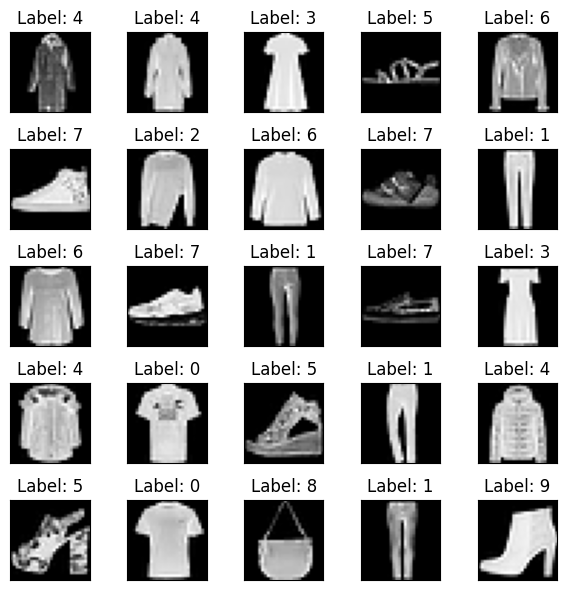

In [4]:
# display images examples

fig, axs = plt.subplots(5, 5, figsize=(6,6))
for ax in axs.flatten():
    img, label = random.choice(train_dataset)
    ax.imshow(np.array(img), cmap='gist_gray')
    ax.set_title('Label: %d' % label)
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()

In [5]:
# data to tensors

train_transform = transforms.Compose([
    transforms.ToTensor(),
])
test_transform = transforms.Compose([
    transforms.ToTensor(),
])

# Set the train transform
train_dataset.transform = train_transform
# Set the test transform
test_dataset.transform = test_transform

In [6]:
# adding validation split

m=len(train_dataset)

train_data, val_data = random_split(train_dataset, [int(len(train_dataset)*0.8), int(m*0.2)])

batch_size=256

# The dataloaders handle shuffling, batching, etc...
train_loader = torch.utils.data.DataLoader(train_data, batch_size=batch_size)
valid_loader = torch.utils.data.DataLoader(val_data, batch_size=batch_size)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size,shuffle=True)

In [7]:
class Encoder(nn.Module):
    
    def __init__(self, encoded_space_dim,fc2_input_dim):
        super().__init__()
        
        # Convolutional section
        self.encoder_cnn = nn.Sequential(
            # First convolutional layer
            nn.Conv2d(1, 8, 3, stride=2, padding=1),
            #nn.BatchNorm2d(8),
            nn.ReLU(True),
            # Second convolutional layer
            nn.Conv2d(8, 16, 3, stride=2, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(True),
            # Third convolutional layer
            nn.Conv2d(16, 32, 3, stride=2, padding=0),
            #nn.BatchNorm2d(32),
            nn.ReLU(True)
        )
        
        # Flatten layer
        self.flatten = nn.Flatten(start_dim=1)

        # Linear section
        self.encoder_lin = nn.Sequential(
            # First linear layer
            nn.Linear(3 * 3 * 32, 128),
            nn.ReLU(True),
            # Second linear layer
            nn.Linear(128, encoded_space_dim)
        )
        
    def forward(self, x):
        # Apply convolutions
        x = self.encoder_cnn(x)
        # Flatten
        x = self.flatten(x)
        # # Apply linear layers
        x = self.encoder_lin(x)
        return x

In [8]:
class Decoder(nn.Module):
    
    def __init__(self, encoded_space_dim,fc2_input_dim=128):
        super().__init__()

        # Linear section
        self.decoder_lin = nn.Sequential(
            # First linear layer
            nn.Linear(encoded_space_dim, 128),
            nn.ReLU(True),
            # Second linear layer
            nn.Linear(128, 3 * 3 * 32),
            nn.ReLU(True)
        )

        # Unflatten
        self.unflatten = nn.Unflatten(dim=1, unflattened_size=(32, 3, 3))

        # Convolutional section
        self.decoder_conv = nn.Sequential(
            # First transposed convolution
            nn.ConvTranspose2d(32, 16, 3, stride=2, output_padding=0),
            nn.BatchNorm2d(16),
            nn.ReLU(True),
            # Second transposed convolution
            nn.ConvTranspose2d(16, 8, 3, stride=2, padding=1, output_padding=1),
            nn.BatchNorm2d(8),
            nn.ReLU(True),
            # Third transposed convolution
            nn.ConvTranspose2d(8, 1, 3, stride=2, padding=1, output_padding=1)
        )
        
    def forward(self, x):
        # Apply linear layers
        x = self.decoder_lin(x)
        # Unflatten
        x = self.unflatten(x)
        # Apply transposed convolutions
        x = self.decoder_conv(x)
        # Apply a sigmoid to force the output to be between 0 and 1 (valid pixel values)
        x = torch.sigmoid(x)
        return x

In [9]:
# Set the random seed for reproducible results
torch.manual_seed(42)

# Initialize the two networks
dim = 4

encoder = Encoder(encoded_space_dim=dim, fc2_input_dim=128)
decoder = Decoder(encoded_space_dim=dim, fc2_input_dim=128)

In [10]:
# Example on the untrained model

img, _ = test_dataset[0]
img = img.unsqueeze(0) # Add the batch dimension in the first axis
print('Original image shape:', img.shape)

# Encode the image
img_enc = encoder(img)
print('Encoded image shape:', img_enc.shape)

# Decode the image
dec_img = decoder(img_enc)
print('Decoded image shape:', dec_img.shape)

Original image shape: torch.Size([1, 1, 28, 28])
Encoded image shape: torch.Size([1, 4])
Decoded image shape: torch.Size([1, 1, 28, 28])


In [11]:
# Define the loss function
loss_fn = torch.nn.MSELoss()

# Define an optimizer (both for the encoder and the decoder!)
lr= 0.001

params_to_optimize = [
    {'params': encoder.parameters()},
    {'params': decoder.parameters()}
]

optim = torch.optim.Adam(params_to_optimize, lr=lr, weight_decay=1e-05)

# Check if the GPU is available
device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
print(f'Selected device: {device}')

# Move both the encoder and the decoder to the selected device
encoder.to(device)

Selected device: cuda


Encoder(
  (encoder_cnn): Sequential(
    (0): Conv2d(1, 8, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(8, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (4): ReLU(inplace=True)
    (5): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2))
    (6): ReLU(inplace=True)
  )
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (encoder_lin): Sequential(
    (0): Linear(in_features=288, out_features=128, bias=True)
    (1): ReLU(inplace=True)
    (2): Linear(in_features=128, out_features=4, bias=True)
  )
)

In [12]:
decoder.to(device)

Decoder(
  (decoder_lin): Sequential(
    (0): Linear(in_features=4, out_features=128, bias=True)
    (1): ReLU(inplace=True)
    (2): Linear(in_features=128, out_features=288, bias=True)
    (3): ReLU(inplace=True)
  )
  (unflatten): Unflatten(dim=1, unflattened_size=(32, 3, 3))
  (decoder_conv): Sequential(
    (0): ConvTranspose2d(32, 16, kernel_size=(3, 3), stride=(2, 2))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(16, 8, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
    (4): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(8, 1, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
  )
)

In [13]:
def train_epoch(encoder, decoder, device, dataloader, loss_fn, optimizer):
    # Set train mode for both the encoder and the decoder
    encoder.train()
    decoder.train()
    train_loss = []
    # Iterate the dataloader (we do not need the label values, this is unsupervised learning)
    for image_batch, _ in dataloader: # with "_" we just ignore the labels (the second element of the dataloader tuple)
        # Move tensor to the proper device
        image_batch = image_batch.to(device)
        # Encode data
        encoded_data = encoder(image_batch)
        # Decode data
        decoded_data = decoder(encoded_data)
        # Evaluate loss
        loss = loss_fn(decoded_data, image_batch)
        # Backward pass
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        # Print batch loss
        print('\t partial train loss (single batch): %f' % (loss.data))
        train_loss.append(loss.detach().cpu().numpy())

    return np.mean(train_loss)

In [14]:
def test_epoch(encoder, decoder, device, dataloader, loss_fn):
    # Set evaluation mode for encoder and decoder
    encoder.eval()
    decoder.eval()
    with torch.no_grad(): # No need to track the gradients
        # Define the lists to store the outputs for each batch
        conc_out = []
        conc_label = []
        for image_batch, _ in dataloader:
            # Move tensor to the proper device
            image_batch = image_batch.to(device)
            # Encode data
            encoded_data = encoder(image_batch)
            # Decode data
            decoded_data = decoder(encoded_data)
            # Append the network output and the original image to the lists
            conc_out.append(decoded_data.cpu())
            conc_label.append(image_batch.cpu())
        # Create a single tensor with all the values in the lists
        conc_out = torch.cat(conc_out)
        conc_label = torch.cat(conc_label) 
        # Evaluate global loss
        val_loss = loss_fn(conc_out, conc_label)
    return val_loss.data

In [15]:
def plot_ae_outputs(encoder,decoder,n=5):
    plt.figure(figsize=(10,4.5))
    for i in range(n):
        ax = plt.subplot(2,n,i+1)
        img = test_dataset[i][0].unsqueeze(0).to(device)
        encoder.eval()
        decoder.eval()
        with torch.no_grad():
            rec_img  = decoder(encoder(img))
        plt.imshow(img.cpu().squeeze().numpy(), cmap='gist_gray')
        ax.get_xaxis().set_visible(False)
        ax.get_yaxis().set_visible(False)  
        if i == n//2:
            ax.set_title('Original images')
        ax = plt.subplot(2, n, i + 1 + n)
        plt.imshow(rec_img.cpu().squeeze().numpy(), cmap='gist_gray')  
        ax.get_xaxis().set_visible(False)
        ax.get_yaxis().set_visible(False)  
        if i == n//2:
            ax.set_title('Reconstructed images')
    plt.show()

	 partial train loss (single batch): 0.248918
	 partial train loss (single batch): 0.234696
	 partial train loss (single batch): 0.232912
	 partial train loss (single batch): 0.224485
	 partial train loss (single batch): 0.223643
	 partial train loss (single batch): 0.215712
	 partial train loss (single batch): 0.221551
	 partial train loss (single batch): 0.213038
	 partial train loss (single batch): 0.207947
	 partial train loss (single batch): 0.208464
	 partial train loss (single batch): 0.203163
	 partial train loss (single batch): 0.207566
	 partial train loss (single batch): 0.197996
	 partial train loss (single batch): 0.199601
	 partial train loss (single batch): 0.193916


	 partial train loss (single batch): 0.190339
	 partial train loss (single batch): 0.192347
	 partial train loss (single batch): 0.187858
	 partial train loss (single batch): 0.180840
	 partial train loss (single batch): 0.188330
	 partial train loss (single batch): 0.178021
	 partial train loss (single batch): 0.180386
	 partial train loss (single batch): 0.178037
	 partial train loss (single batch): 0.176543
	 partial train loss (single batch): 0.177427
	 partial train loss (single batch): 0.174238
	 partial train loss (single batch): 0.172597
	 partial train loss (single batch): 0.175677
	 partial train loss (single batch): 0.169768
	 partial train loss (single batch): 0.174692


	 partial train loss (single batch): 0.169660
	 partial train loss (single batch): 0.164202
	 partial train loss (single batch): 0.164697
	 partial train loss (single batch): 0.164492
	 partial train loss (single batch): 0.160705
	 partial train loss (single batch): 0.159328
	 partial train loss (single batch): 0.160497
	 partial train loss (single batch): 0.158109
	 partial train loss (single batch): 0.160355
	 partial train loss (single batch): 0.159811
	 partial train loss (single batch): 0.154585
	 partial train loss (single batch): 0.155408
	 partial train loss (single batch): 0.151316
	 partial train loss (single batch): 0.152362
	 partial train loss (single batch): 0.156433


	 partial train loss (single batch): 0.149960
	 partial train loss (single batch): 0.154203
	 partial train loss (single batch): 0.147121
	 partial train loss (single batch): 0.143963
	 partial train loss (single batch): 0.144821
	 partial train loss (single batch): 0.144733
	 partial train loss (single batch): 0.145609
	 partial train loss (single batch): 0.146122
	 partial train loss (single batch): 0.142455
	 partial train loss (single batch): 0.143939
	 partial train loss (single batch): 0.144769
	 partial train loss (single batch): 0.141731
	 partial train loss (single batch): 0.139501
	 partial train loss (single batch): 0.137362
	 partial train loss (single batch): 0.133570


	 partial train loss (single batch): 0.139842
	 partial train loss (single batch): 0.138964
	 partial train loss (single batch): 0.134088
	 partial train loss (single batch): 0.135047
	 partial train loss (single batch): 0.132368
	 partial train loss (single batch): 0.133636
	 partial train loss (single batch): 0.130667
	 partial train loss (single batch): 0.126690
	 partial train loss (single batch): 0.131812
	 partial train loss (single batch): 0.127088
	 partial train loss (single batch): 0.129138
	 partial train loss (single batch): 0.125316
	 partial train loss (single batch): 0.127059
	 partial train loss (single batch): 0.127680
	 partial train loss (single batch): 0.125718


	 partial train loss (single batch): 0.122936
	 partial train loss (single batch): 0.121911
	 partial train loss (single batch): 0.120405
	 partial train loss (single batch): 0.121180
	 partial train loss (single batch): 0.121507
	 partial train loss (single batch): 0.119487
	 partial train loss (single batch): 0.118905
	 partial train loss (single batch): 0.120546
	 partial train loss (single batch): 0.116142
	 partial train loss (single batch): 0.117103
	 partial train loss (single batch): 0.114472
	 partial train loss (single batch): 0.113025
	 partial train loss (single batch): 0.114999
	 partial train loss (single batch): 0.111782
	 partial train loss (single batch): 0.111279


... (4 outputs left out)

	 partial train loss (single batch): 0.071272
	 partial train loss (single batch): 0.068313
	 partial train loss (single batch): 0.069901
	 partial train loss (single batch): 0.068077
	 partial train loss (single batch): 0.067378
	 partial train loss (single batch): 0.068364
	 partial train loss (single batch): 0.067078
	 partial train loss (single batch): 0.066147
	 partial train loss (single batch): 0.068365
	 partial train loss (single batch): 0.067133
	 partial train loss (single batch): 0.067189
	 partial train loss (single batch): 0.065101
	 partial train loss (single batch): 0.065355
	 partial train loss (single batch): 0.064339
	 partial train loss (single batch): 0.060978


	 partial train loss (single batch): 0.064853
	 partial train loss (single batch): 0.063161
	 partial train loss (single batch): 0.062249
	 partial train loss (single batch): 0.064607
	 partial train loss (single batch): 0.062822
	 partial train loss (single batch): 0.059713
	 partial train loss (single batch): 0.060653
	 partial train loss (single batch): 0.059922
	 partial train loss (single batch): 0.059299
	 partial train loss (single batch): 0.058619
	 partial train loss (single batch): 0.058485
	 partial train loss (single batch): 0.059395
	 partial train loss (single batch): 0.058067
	 partial train loss (single batch): 0.058018
	 partial train loss (single batch): 0.057804


	 partial train loss (single batch): 0.059706
	 partial train loss (single batch): 0.057154
	 partial train loss (single batch): 0.054571
	 partial train loss (single batch): 0.056781
	 partial train loss (single batch): 0.056822
	 partial train loss (single batch): 0.054227
	 partial train loss (single batch): 0.054261
	 partial train loss (single batch): 0.054995



 EPOCH 1/30 	 train loss 0.117 	 val loss 0.054


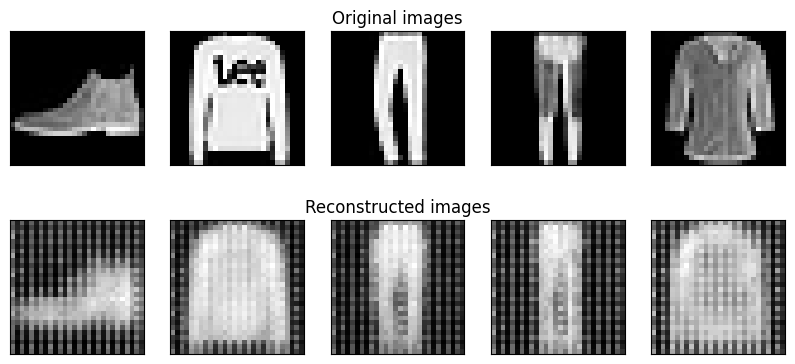

	 partial train loss (single batch): 0.054974
	 partial train loss (single batch): 0.053505
	 partial train loss (single batch): 0.054506
	 partial train loss (single batch): 0.052839
	 partial train loss (single batch): 0.053954
	 partial train loss (single batch): 0.051911
	 partial train loss (single batch): 0.055590
	 partial train loss (single batch): 0.051667


	 partial train loss (single batch): 0.051237
	 partial train loss (single batch): 0.051403
	 partial train loss (single batch): 0.051374
	 partial train loss (single batch): 0.052022
	 partial train loss (single batch): 0.050165
	 partial train loss (single batch): 0.051545
	 partial train loss (single batch): 0.050601


	 partial train loss (single batch): 0.049654
	 partial train loss (single batch): 0.050927
	 partial train loss (single batch): 0.050145
	 partial train loss (single batch): 0.047973
	 partial train loss (single batch): 0.050871
	 partial train loss (single batch): 0.047097
	 partial train loss (single batch): 0.047849
	 partial train loss (single batch): 0.048798


	 partial train loss (single batch): 0.048143
	 partial train loss (single batch): 0.048196
	 partial train loss (single batch): 0.046932
	 partial train loss (single batch): 0.047900
	 partial train loss (single batch): 0.047811
	 partial train loss (single batch): 0.045902
	 partial train loss (single batch): 0.047245


	 partial train loss (single batch): 0.046583
	 partial train loss (single batch): 0.044710
	 partial train loss (single batch): 0.045647
	 partial train loss (single batch): 0.046626
	 partial train loss (single batch): 0.044847
	 partial train loss (single batch): 0.044474
	 partial train loss (single batch): 0.044290
	 partial train loss (single batch): 0.044070


	 partial train loss (single batch): 0.044694
	 partial train loss (single batch): 0.045172
	 partial train loss (single batch): 0.043471
	 partial train loss (single batch): 0.043669
	 partial train loss (single batch): 0.043002
	 partial train loss (single batch): 0.042318
	 partial train loss (single batch): 0.045021


... (17 outputs left out)

	 partial train loss (single batch): 0.030823
	 partial train loss (single batch): 0.030472
	 partial train loss (single batch): 0.031307
	 partial train loss (single batch): 0.030455
	 partial train loss (single batch): 0.029398
	 partial train loss (single batch): 0.029298


	 partial train loss (single batch): 0.029636
	 partial train loss (single batch): 0.030222
	 partial train loss (single batch): 0.031198
	 partial train loss (single batch): 0.029168
	 partial train loss (single batch): 0.030808
	 partial train loss (single batch): 0.031888
	 partial train loss (single batch): 0.029856
	 partial train loss (single batch): 0.028018
	 partial train loss (single batch): 0.030076


	 partial train loss (single batch): 0.030670
	 partial train loss (single batch): 0.028324
	 partial train loss (single batch): 0.030309
	 partial train loss (single batch): 0.028870



 EPOCH 2/30 	 train loss 0.038 	 val loss 0.030


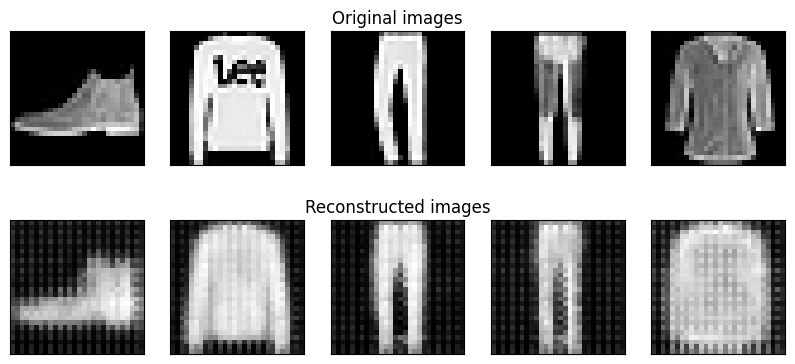

	 partial train loss (single batch): 0.030617
	 partial train loss (single batch): 0.030176
	 partial train loss (single batch): 0.030647
	 partial train loss (single batch): 0.029175
	 partial train loss (single batch): 0.030367
	 partial train loss (single batch): 0.029347
	 partial train loss (single batch): 0.031910
	 partial train loss (single batch): 0.028698


	 partial train loss (single batch): 0.029138
	 partial train loss (single batch): 0.029057
	 partial train loss (single batch): 0.029866
	 partial train loss (single batch): 0.028885
	 partial train loss (single batch): 0.029054
	 partial train loss (single batch): 0.029695


	 partial train loss (single batch): 0.029653
	 partial train loss (single batch): 0.029366
	 partial train loss (single batch): 0.029644
	 partial train loss (single batch): 0.029912
	 partial train loss (single batch): 0.028575
	 partial train loss (single batch): 0.030402
	 partial train loss (single batch): 0.028115
	 partial train loss (single batch): 0.028249


	 partial train loss (single batch): 0.029983
	 partial train loss (single batch): 0.029700
	 partial train loss (single batch): 0.029240
	 partial train loss (single batch): 0.028239
	 partial train loss (single batch): 0.029840
	 partial train loss (single batch): 0.028980
	 partial train loss (single batch): 0.027862


	 partial train loss (single batch): 0.027960
	 partial train loss (single batch): 0.028334
	 partial train loss (single batch): 0.027535
	 partial train loss (single batch): 0.028377
	 partial train loss (single batch): 0.029645
	 partial train loss (single batch): 0.028197
	 partial train loss (single batch): 0.028105


	 partial train loss (single batch): 0.027681
	 partial train loss (single batch): 0.027740
	 partial train loss (single batch): 0.027699
	 partial train loss (single batch): 0.028629
	 partial train loss (single batch): 0.027723
	 partial train loss (single batch): 0.027691
	 partial train loss (single batch): 0.027941
	 partial train loss (single batch): 0.026799


... (18 outputs left out)

	 partial train loss (single batch): 0.024879
	 partial train loss (single batch): 0.026492
	 partial train loss (single batch): 0.024950
	 partial train loss (single batch): 0.025167
	 partial train loss (single batch): 0.026029
	 partial train loss (single batch): 0.025152
	 partial train loss (single batch): 0.023933
	 partial train loss (single batch): 0.024046


	 partial train loss (single batch): 0.024331
	 partial train loss (single batch): 0.024829
	 partial train loss (single batch): 0.026291
	 partial train loss (single batch): 0.023771
	 partial train loss (single batch): 0.025592
	 partial train loss (single batch): 0.026649


	 partial train loss (single batch): 0.024707
	 partial train loss (single batch): 0.023032
	 partial train loss (single batch): 0.025007
	 partial train loss (single batch): 0.025640
	 partial train loss (single batch): 0.023454
	 partial train loss (single batch): 0.025724
	 partial train loss (single batch): 0.023619



 EPOCH 3/30 	 train loss 0.027 	 val loss 0.025


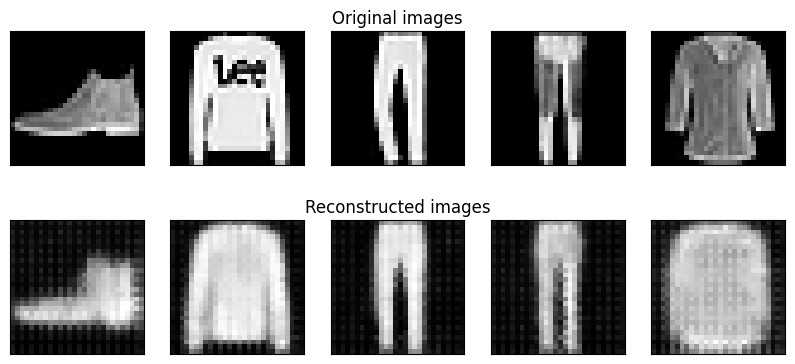

	 partial train loss (single batch): 0.025722
	 partial train loss (single batch): 0.025403
	 partial train loss (single batch): 0.025816
	 partial train loss (single batch): 0.024271
	 partial train loss (single batch): 0.025581
	 partial train loss (single batch): 0.024595
	 partial train loss (single batch): 0.026997
	 partial train loss (single batch): 0.024010


	 partial train loss (single batch): 0.024729
	 partial train loss (single batch): 0.024350
	 partial train loss (single batch): 0.025441
	 partial train loss (single batch): 0.023883
	 partial train loss (single batch): 0.024669
	 partial train loss (single batch): 0.024937


	 partial train loss (single batch): 0.025011
	 partial train loss (single batch): 0.024864
	 partial train loss (single batch): 0.025111
	 partial train loss (single batch): 0.025478
	 partial train loss (single batch): 0.024264
	 partial train loss (single batch): 0.025594
	 partial train loss (single batch): 0.023912
	 partial train loss (single batch): 0.023703


	 partial train loss (single batch): 0.025817
	 partial train loss (single batch): 0.025585
	 partial train loss (single batch): 0.024864
	 partial train loss (single batch): 0.023954
	 partial train loss (single batch): 0.025495


	 partial train loss (single batch): 0.024832
	 partial train loss (single batch): 0.023824
	 partial train loss (single batch): 0.023315
	 partial train loss (single batch): 0.024061
	 partial train loss (single batch): 0.023403
	 partial train loss (single batch): 0.024323
	 partial train loss (single batch): 0.025623
	 partial train loss (single batch): 0.024370


	 partial train loss (single batch): 0.024226
	 partial train loss (single batch): 0.023778
	 partial train loss (single batch): 0.023852
	 partial train loss (single batch): 0.023571
	 partial train loss (single batch): 0.024514


... (20 outputs left out)

	 partial train loss (single batch): 0.024002
	 partial train loss (single batch): 0.023045
	 partial train loss (single batch): 0.021807
	 partial train loss (single batch): 0.021985
	 partial train loss (single batch): 0.022288
	 partial train loss (single batch): 0.022662
	 partial train loss (single batch): 0.024217
	 partial train loss (single batch): 0.021556


	 partial train loss (single batch): 0.023495
	 partial train loss (single batch): 0.024557
	 partial train loss (single batch): 0.022529
	 partial train loss (single batch): 0.021002
	 partial train loss (single batch): 0.022898


	 partial train loss (single batch): 0.023564
	 partial train loss (single batch): 0.021634
	 partial train loss (single batch): 0.023687
	 partial train loss (single batch): 0.021547



 EPOCH 4/30 	 train loss 0.024 	 val loss 0.023


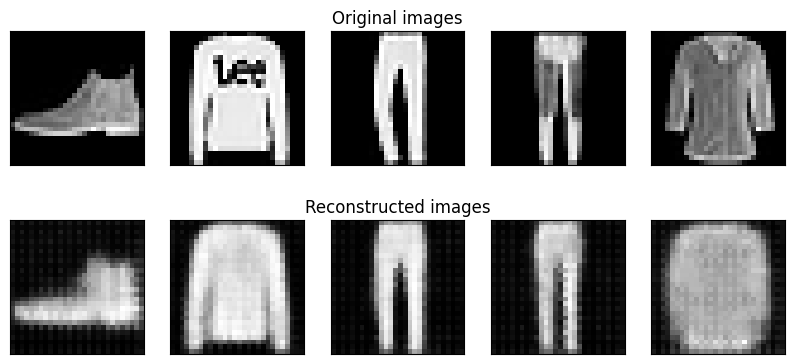

	 partial train loss (single batch): 0.023530
	 partial train loss (single batch): 0.023439
	 partial train loss (single batch): 0.023822
	 partial train loss (single batch): 0.022254
	 partial train loss (single batch): 0.023496
	 partial train loss (single batch): 0.022778
	 partial train loss (single batch): 0.025058
	 partial train loss (single batch): 0.022075


	 partial train loss (single batch): 0.023024
	 partial train loss (single batch): 0.022397
	 partial train loss (single batch): 0.023585
	 partial train loss (single batch): 0.021955
	 partial train loss (single batch): 0.022695


	 partial train loss (single batch): 0.023033
	 partial train loss (single batch): 0.023251
	 partial train loss (single batch): 0.022966
	 partial train loss (single batch): 0.023276
	 partial train loss (single batch): 0.023677
	 partial train loss (single batch): 0.022446
	 partial train loss (single batch): 0.023652
	 partial train loss (single batch): 0.022265
	 partial train loss (single batch): 0.021889


	 partial train loss (single batch): 0.024025
	 partial train loss (single batch): 0.023841
	 partial train loss (single batch): 0.023026
	 partial train loss (single batch): 0.022230
	 partial train loss (single batch): 0.023707


	 partial train loss (single batch): 0.023106
	 partial train loss (single batch): 0.022032
	 partial train loss (single batch): 0.021424
	 partial train loss (single batch): 0.022250
	 partial train loss (single batch): 0.021745
	 partial train loss (single batch): 0.022620
	 partial train loss (single batch): 0.023951
	 partial train loss (single batch): 0.022703
	 partial train loss (single batch): 0.022611


	 partial train loss (single batch): 0.022001
	 partial train loss (single batch): 0.022303
	 partial train loss (single batch): 0.021858
	 partial train loss (single batch): 0.022632
	 partial train loss (single batch): 0.022238


... (18 outputs left out)

	 partial train loss (single batch): 0.023212
	 partial train loss (single batch): 0.022284
	 partial train loss (single batch): 0.021304
	 partial train loss (single batch): 0.023062
	 partial train loss (single batch): 0.021733
	 partial train loss (single batch): 0.022104
	 partial train loss (single batch): 0.022883
	 partial train loss (single batch): 0.022088
	 partial train loss (single batch): 0.020729
	 partial train loss (single batch): 0.020946


	 partial train loss (single batch): 0.021345
	 partial train loss (single batch): 0.021653
	 partial train loss (single batch): 0.023175
	 partial train loss (single batch): 0.020561


	 partial train loss (single batch): 0.022514
	 partial train loss (single batch): 0.023515
	 partial train loss (single batch): 0.021545
	 partial train loss (single batch): 0.020017
	 partial train loss (single batch): 0.021928
	 partial train loss (single batch): 0.022597
	 partial train loss (single batch): 0.020714
	 partial train loss (single batch): 0.022774
	 partial train loss (single batch): 0.020409



 EPOCH 5/30 	 train loss 0.022 	 val loss 0.022


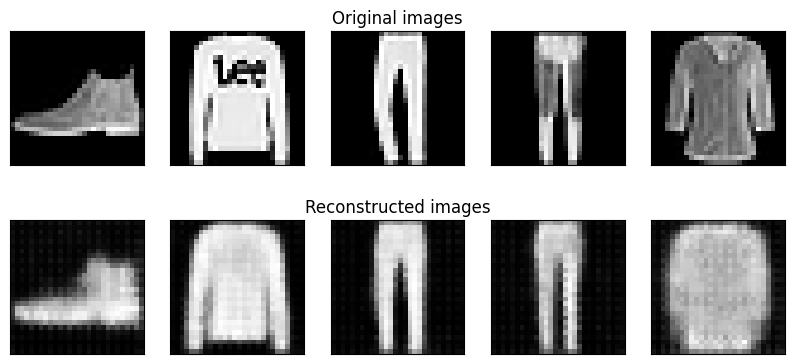

	 partial train loss (single batch): 0.022480
	 partial train loss (single batch): 0.022471
	 partial train loss (single batch): 0.022829
	 partial train loss (single batch): 0.021268
	 partial train loss (single batch): 0.022510
	 partial train loss (single batch): 0.021799
	 partial train loss (single batch): 0.024217
	 partial train loss (single batch): 0.021165


	 partial train loss (single batch): 0.022166
	 partial train loss (single batch): 0.021495
	 partial train loss (single batch): 0.022524
	 partial train loss (single batch): 0.020983
	 partial train loss (single batch): 0.021744
	 partial train loss (single batch): 0.021995


	 partial train loss (single batch): 0.022497
	 partial train loss (single batch): 0.022082
	 partial train loss (single batch): 0.022244
	 partial train loss (single batch): 0.022856
	 partial train loss (single batch): 0.021459
	 partial train loss (single batch): 0.022730
	 partial train loss (single batch): 0.021522
	 partial train loss (single batch): 0.020922


	 partial train loss (single batch): 0.023137
	 partial train loss (single batch): 0.023007
	 partial train loss (single batch): 0.022101
	 partial train loss (single batch): 0.021500
	 partial train loss (single batch): 0.022776
	 partial train loss (single batch): 0.022072


	 partial train loss (single batch): 0.021178
	 partial train loss (single batch): 0.020484
	 partial train loss (single batch): 0.021296
	 partial train loss (single batch): 0.021007
	 partial train loss (single batch): 0.021733
	 partial train loss (single batch): 0.023082
	 partial train loss (single batch): 0.021894
	 partial train loss (single batch): 0.021728


	 partial train loss (single batch): 0.021180
	 partial train loss (single batch): 0.021490
	 partial train loss (single batch): 0.020872
	 partial train loss (single batch): 0.021767
	 partial train loss (single batch): 0.021405
	 partial train loss (single batch): 0.021158


... (18 outputs left out)

	 partial train loss (single batch): 0.022289
	 partial train loss (single batch): 0.021103
	 partial train loss (single batch): 0.021452
	 partial train loss (single batch): 0.022162
	 partial train loss (single batch): 0.021486
	 partial train loss (single batch): 0.020064
	 partial train loss (single batch): 0.020260
	 partial train loss (single batch): 0.020734
	 partial train loss (single batch): 0.021062


	 partial train loss (single batch): 0.022529
	 partial train loss (single batch): 0.019932
	 partial train loss (single batch): 0.021888
	 partial train loss (single batch): 0.022837
	 partial train loss (single batch): 0.020915


	 partial train loss (single batch): 0.019409
	 partial train loss (single batch): 0.021268
	 partial train loss (single batch): 0.021989
	 partial train loss (single batch): 0.020165
	 partial train loss (single batch): 0.022142
	 partial train loss (single batch): 0.019711



 EPOCH 6/30 	 train loss 0.022 	 val loss 0.021


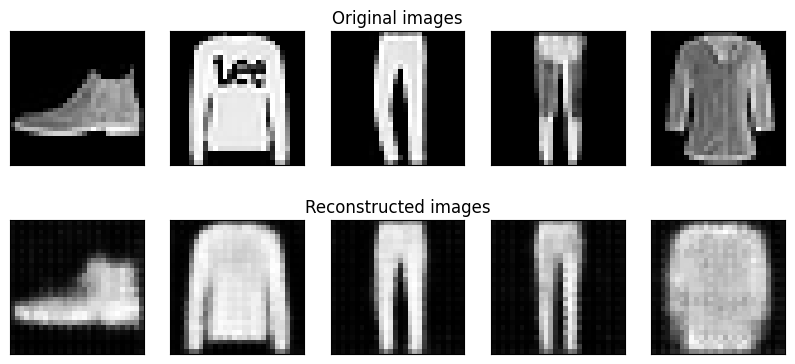

	 partial train loss (single batch): 0.021862
	 partial train loss (single batch): 0.021809
	 partial train loss (single batch): 0.022203
	 partial train loss (single batch): 0.020653
	 partial train loss (single batch): 0.021915
	 partial train loss (single batch): 0.021178
	 partial train loss (single batch): 0.023620


	 partial train loss (single batch): 0.020537
	 partial train loss (single batch): 0.021599
	 partial train loss (single batch): 0.020846
	 partial train loss (single batch): 0.021934
	 partial train loss (single batch): 0.020368
	 partial train loss (single batch): 0.021229
	 partial train loss (single batch): 0.021383


	 partial train loss (single batch): 0.021973
	 partial train loss (single batch): 0.021499
	 partial train loss (single batch): 0.021590
	 partial train loss (single batch): 0.022252
	 partial train loss (single batch): 0.020865
	 partial train loss (single batch): 0.022166
	 partial train loss (single batch): 0.020948


	 partial train loss (single batch): 0.020311
	 partial train loss (single batch): 0.022502
	 partial train loss (single batch): 0.022453
	 partial train loss (single batch): 0.021529
	 partial train loss (single batch): 0.020967
	 partial train loss (single batch): 0.022194
	 partial train loss (single batch): 0.021428


	 partial train loss (single batch): 0.020579
	 partial train loss (single batch): 0.019873
	 partial train loss (single batch): 0.020669
	 partial train loss (single batch): 0.020438
	 partial train loss (single batch): 0.021203
	 partial train loss (single batch): 0.022472
	 partial train loss (single batch): 0.021380


	 partial train loss (single batch): 0.021210
	 partial train loss (single batch): 0.020640
	 partial train loss (single batch): 0.020991
	 partial train loss (single batch): 0.020313
	 partial train loss (single batch): 0.021237
	 partial train loss (single batch): 0.020905
	 partial train loss (single batch): 0.020649


... (18 outputs left out)

	 partial train loss (single batch): 0.020188
	 partial train loss (single batch): 0.021773
	 partial train loss (single batch): 0.020699
	 partial train loss (single batch): 0.021007
	 partial train loss (single batch): 0.021728
	 partial train loss (single batch): 0.021042
	 partial train loss (single batch): 0.019602
	 partial train loss (single batch): 0.019816


	 partial train loss (single batch): 0.020284
	 partial train loss (single batch): 0.020648
	 partial train loss (single batch): 0.022137
	 partial train loss (single batch): 0.019462
	 partial train loss (single batch): 0.021465
	 partial train loss (single batch): 0.022388


	 partial train loss (single batch): 0.020474
	 partial train loss (single batch): 0.019007
	 partial train loss (single batch): 0.020844
	 partial train loss (single batch): 0.021546
	 partial train loss (single batch): 0.019815
	 partial train loss (single batch): 0.021677
	 partial train loss (single batch): 0.019249



 EPOCH 7/30 	 train loss 0.021 	 val loss 0.021


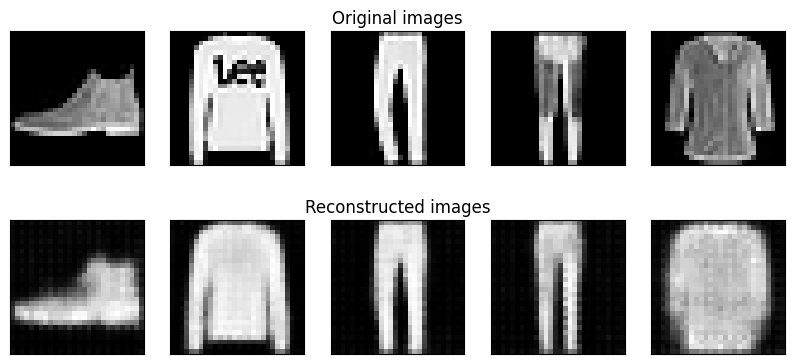

	 partial train loss (single batch): 0.021415
	 partial train loss (single batch): 0.021324
	 partial train loss (single batch): 0.021842
	 partial train loss (single batch): 0.020212
	 partial train loss (single batch): 0.021462
	 partial train loss (single batch): 0.020786
	 partial train loss (single batch): 0.023186
	 partial train loss (single batch): 0.020174


	 partial train loss (single batch): 0.021203
	 partial train loss (single batch): 0.020424
	 partial train loss (single batch): 0.021530
	 partial train loss (single batch): 0.019941
	 partial train loss (single batch): 0.020839
	 partial train loss (single batch): 0.020973


	 partial train loss (single batch): 0.021594
	 partial train loss (single batch): 0.021081
	 partial train loss (single batch): 0.021193
	 partial train loss (single batch): 0.021805
	 partial train loss (single batch): 0.020457
	 partial train loss (single batch): 0.021790
	 partial train loss (single batch): 0.020520
	 partial train loss (single batch): 0.019929


	 partial train loss (single batch): 0.022071
	 partial train loss (single batch): 0.022092
	 partial train loss (single batch): 0.021161
	 partial train loss (single batch): 0.020641
	 partial train loss (single batch): 0.021783
	 partial train loss (single batch): 0.021026


	 partial train loss (single batch): 0.020212
	 partial train loss (single batch): 0.019513
	 partial train loss (single batch): 0.020239
	 partial train loss (single batch): 0.020079
	 partial train loss (single batch): 0.020829
	 partial train loss (single batch): 0.022063
	 partial train loss (single batch): 0.021071
	 partial train loss (single batch): 0.020861


	 partial train loss (single batch): 0.020292
	 partial train loss (single batch): 0.020626
	 partial train loss (single batch): 0.019977
	 partial train loss (single batch): 0.020915
	 partial train loss (single batch): 0.020549


... (19 outputs left out)

	 partial train loss (single batch): 0.019287
	 partial train loss (single batch): 0.019514
	 partial train loss (single batch): 0.020004
	 partial train loss (single batch): 0.020392


	 partial train loss (single batch): 0.021838
	 partial train loss (single batch): 0.019177
	 partial train loss (single batch): 0.021171
	 partial train loss (single batch): 0.022087
	 partial train loss (single batch): 0.020183
	 partial train loss (single batch): 0.018692
	 partial train loss (single batch): 0.020541
	 partial train loss (single batch): 0.021263
	 partial train loss (single batch): 0.019553


	 partial train loss (single batch): 0.021343
	 partial train loss (single batch): 0.018958



 EPOCH 8/30 	 train loss 0.021 	 val loss 0.021


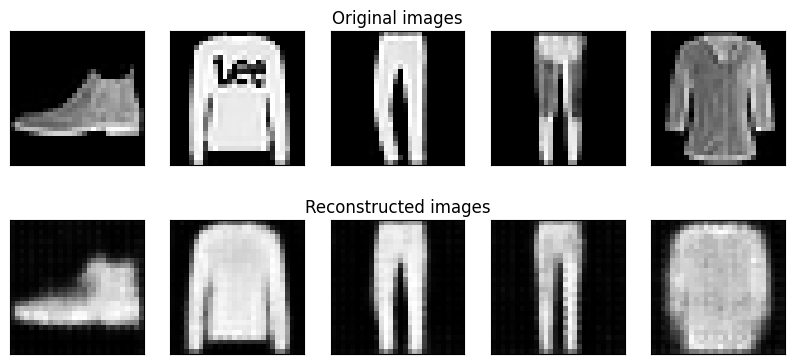

	 partial train loss (single batch): 0.021096
	 partial train loss (single batch): 0.020979
	 partial train loss (single batch): 0.021538
	 partial train loss (single batch): 0.019891
	 partial train loss (single batch): 0.021162
	 partial train loss (single batch): 0.020476
	 partial train loss (single batch): 0.022860
	 partial train loss (single batch): 0.019844
	 partial train loss (single batch): 0.020921
	 partial train loss (single batch): 0.020066
	 partial train loss (single batch): 0.021237
	 partial train loss (single batch): 0.019598
	 partial train loss (single batch): 0.020575


	 partial train loss (single batch): 0.020629
	 partial train loss (single batch): 0.021361
	 partial train loss (single batch): 0.020822
	 partial train loss (single batch): 0.020916
	 partial train loss (single batch): 0.021559
	 partial train loss (single batch): 0.020183
	 partial train loss (single batch): 0.021539
	 partial train loss (single batch): 0.020260
	 partial train loss (single batch): 0.019654
	 partial train loss (single batch): 0.021795
	 partial train loss (single batch): 0.021840
	 partial train loss (single batch): 0.020906
	 partial train loss (single batch): 0.020445
	 partial train loss (single batch): 0.021509


	 partial train loss (single batch): 0.020734
	 partial train loss (single batch): 0.019947
	 partial train loss (single batch): 0.019236
	 partial train loss (single batch): 0.019956
	 partial train loss (single batch): 0.019847
	 partial train loss (single batch): 0.020516
	 partial train loss (single batch): 0.021784
	 partial train loss (single batch): 0.020874
	 partial train loss (single batch): 0.020571
	 partial train loss (single batch): 0.020062
	 partial train loss (single batch): 0.020362
	 partial train loss (single batch): 0.019685
	 partial train loss (single batch): 0.020658


	 partial train loss (single batch): 0.020246
	 partial train loss (single batch): 0.020000
	 partial train loss (single batch): 0.020787
	 partial train loss (single batch): 0.018871
	 partial train loss (single batch): 0.020781
	 partial train loss (single batch): 0.021909
	 partial train loss (single batch): 0.019710
	 partial train loss (single batch): 0.020676
	 partial train loss (single batch): 0.020742
	 partial train loss (single batch): 0.022557
	 partial train loss (single batch): 0.021017
	 partial train loss (single batch): 0.020756
	 partial train loss (single batch): 0.022187


	 partial train loss (single batch): 0.020909
	 partial train loss (single batch): 0.020980
	 partial train loss (single batch): 0.019098
	 partial train loss (single batch): 0.022168
	 partial train loss (single batch): 0.020025
	 partial train loss (single batch): 0.019740
	 partial train loss (single batch): 0.021719
	 partial train loss (single batch): 0.021198
	 partial train loss (single batch): 0.021035
	 partial train loss (single batch): 0.020203
	 partial train loss (single batch): 0.020988
	 partial train loss (single batch): 0.018940
	 partial train loss (single batch): 0.020276
	 partial train loss (single batch): 0.020547


	 partial train loss (single batch): 0.019839
	 partial train loss (single batch): 0.020801
	 partial train loss (single batch): 0.019982
	 partial train loss (single batch): 0.021732
	 partial train loss (single batch): 0.020079
	 partial train loss (single batch): 0.019915
	 partial train loss (single batch): 0.021012
	 partial train loss (single batch): 0.020566
	 partial train loss (single batch): 0.021119
	 partial train loss (single batch): 0.019629
	 partial train loss (single batch): 0.021052
	 partial train loss (single batch): 0.020022
	 partial train loss (single batch): 0.020377
	 partial train loss (single batch): 0.019703


... (5 outputs left out)

	 partial train loss (single batch): 0.021632
	 partial train loss (single batch): 0.020844
	 partial train loss (single batch): 0.020057
	 partial train loss (single batch): 0.019548
	 partial train loss (single batch): 0.020292
	 partial train loss (single batch): 0.020344
	 partial train loss (single batch): 0.021015
	 partial train loss (single batch): 0.020967
	 partial train loss (single batch): 0.019223
	 partial train loss (single batch): 0.019469
	 partial train loss (single batch): 0.020697
	 partial train loss (single batch): 0.021515
	 partial train loss (single batch): 0.021013
	 partial train loss (single batch): 0.020440


	 partial train loss (single batch): 0.020928
	 partial train loss (single batch): 0.021523
	 partial train loss (single batch): 0.020579
	 partial train loss (single batch): 0.021394
	 partial train loss (single batch): 0.020598
	 partial train loss (single batch): 0.019571
	 partial train loss (single batch): 0.021200
	 partial train loss (single batch): 0.020197
	 partial train loss (single batch): 0.020459
	 partial train loss (single batch): 0.021244
	 partial train loss (single batch): 0.020539
	 partial train loss (single batch): 0.019051
	 partial train loss (single batch): 0.019286
	 partial train loss (single batch): 0.019814


	 partial train loss (single batch): 0.020144
	 partial train loss (single batch): 0.021563
	 partial train loss (single batch): 0.018988
	 partial train loss (single batch): 0.020930
	 partial train loss (single batch): 0.021890
	 partial train loss (single batch): 0.019946
	 partial train loss (single batch): 0.018468
	 partial train loss (single batch): 0.020335
	 partial train loss (single batch): 0.021039
	 partial train loss (single batch): 0.019320
	 partial train loss (single batch): 0.021157
	 partial train loss (single batch): 0.018686



 EPOCH 9/30 	 train loss 0.021 	 val loss 0.020


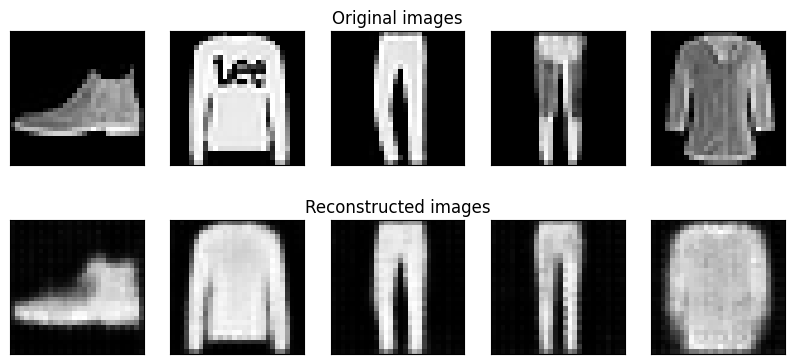

	 partial train loss (single batch): 0.020840
	 partial train loss (single batch): 0.020680
	 partial train loss (single batch): 0.021376
	 partial train loss (single batch): 0.019671
	 partial train loss (single batch): 0.020932
	 partial train loss (single batch): 0.020270
	 partial train loss (single batch): 0.022604
	 partial train loss (single batch): 0.019656


	 partial train loss (single batch): 0.020682
	 partial train loss (single batch): 0.019824
	 partial train loss (single batch): 0.021000
	 partial train loss (single batch): 0.019293
	 partial train loss (single batch): 0.020387
	 partial train loss (single batch): 0.020373


	 partial train loss (single batch): 0.021095
	 partial train loss (single batch): 0.020598
	 partial train loss (single batch): 0.020630
	 partial train loss (single batch): 0.021321
	 partial train loss (single batch): 0.019910
	 partial train loss (single batch): 0.021330
	 partial train loss (single batch): 0.019974
	 partial train loss (single batch): 0.019459


	 partial train loss (single batch): 0.021535
	 partial train loss (single batch): 0.021653
	 partial train loss (single batch): 0.020691
	 partial train loss (single batch): 0.020264
	 partial train loss (single batch): 0.021256
	 partial train loss (single batch): 0.020546


	 partial train loss (single batch): 0.019701
	 partial train loss (single batch): 0.019005
	 partial train loss (single batch): 0.019722
	 partial train loss (single batch): 0.019603
	 partial train loss (single batch): 0.020312
	 partial train loss (single batch): 0.021593
	 partial train loss (single batch): 0.020669


	 partial train loss (single batch): 0.020404
	 partial train loss (single batch): 0.019857
	 partial train loss (single batch): 0.020153
	 partial train loss (single batch): 0.019522
	 partial train loss (single batch): 0.020447
	 partial train loss (single batch): 0.020028
	 partial train loss (single batch): 0.019739


... (18 outputs left out)

	 partial train loss (single batch): 0.021035
	 partial train loss (single batch): 0.020003
	 partial train loss (single batch): 0.020278
	 partial train loss (single batch): 0.021076
	 partial train loss (single batch): 0.020367
	 partial train loss (single batch): 0.018871
	 partial train loss (single batch): 0.019097


	 partial train loss (single batch): 0.019680
	 partial train loss (single batch): 0.019961
	 partial train loss (single batch): 0.021378
	 partial train loss (single batch): 0.018797
	 partial train loss (single batch): 0.020754
	 partial train loss (single batch): 0.021723
	 partial train loss (single batch): 0.019806


	 partial train loss (single batch): 0.018310
	 partial train loss (single batch): 0.020120
	 partial train loss (single batch): 0.020867
	 partial train loss (single batch): 0.019158
	 partial train loss (single batch): 0.020935
	 partial train loss (single batch): 0.018437



 EPOCH 10/30 	 train loss 0.020 	 val loss 0.020


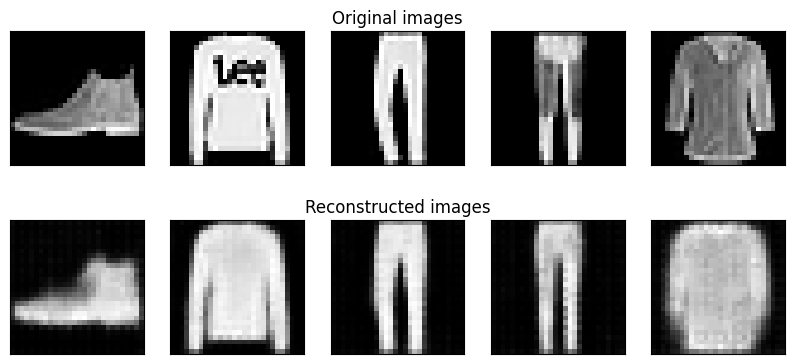

	 partial train loss (single batch): 0.020627
	 partial train loss (single batch): 0.020508
	 partial train loss (single batch): 0.021185
	 partial train loss (single batch): 0.019503
	 partial train loss (single batch): 0.020748
	 partial train loss (single batch): 0.020105
	 partial train loss (single batch): 0.022406


	 partial train loss (single batch): 0.019465
	 partial train loss (single batch): 0.020501
	 partial train loss (single batch): 0.019622
	 partial train loss (single batch): 0.020824
	 partial train loss (single batch): 0.019037
	 partial train loss (single batch): 0.020261


	 partial train loss (single batch): 0.020136
	 partial train loss (single batch): 0.020918
	 partial train loss (single batch): 0.020408
	 partial train loss (single batch): 0.020472
	 partial train loss (single batch): 0.021128
	 partial train loss (single batch): 0.019702
	 partial train loss (single batch): 0.021201
	 partial train loss (single batch): 0.019794


	 partial train loss (single batch): 0.019284
	 partial train loss (single batch): 0.021362
	 partial train loss (single batch): 0.021530
	 partial train loss (single batch): 0.020523
	 partial train loss (single batch): 0.020098
	 partial train loss (single batch): 0.021079


	 partial train loss (single batch): 0.020364
	 partial train loss (single batch): 0.019535
	 partial train loss (single batch): 0.018848
	 partial train loss (single batch): 0.019525
	 partial train loss (single batch): 0.019405
	 partial train loss (single batch): 0.020125
	 partial train loss (single batch): 0.021397


	 partial train loss (single batch): 0.020538
	 partial train loss (single batch): 0.020129
	 partial train loss (single batch): 0.019717
	 partial train loss (single batch): 0.019926
	 partial train loss (single batch): 0.019362
	 partial train loss (single batch): 0.020278
	 partial train loss (single batch): 0.019825


... (19 outputs left out)

	 partial train loss (single batch): 0.020955
	 partial train loss (single batch): 0.020238
	 partial train loss (single batch): 0.018725
	 partial train loss (single batch): 0.018932
	 partial train loss (single batch): 0.019587
	 partial train loss (single batch): 0.019798
	 partial train loss (single batch): 0.021239


	 partial train loss (single batch): 0.018662
	 partial train loss (single batch): 0.020611
	 partial train loss (single batch): 0.021557
	 partial train loss (single batch): 0.019663
	 partial train loss (single batch): 0.018155
	 partial train loss (single batch): 0.019948


	 partial train loss (single batch): 0.020714
	 partial train loss (single batch): 0.019051
	 partial train loss (single batch): 0.020763
	 partial train loss (single batch): 0.018300



 EPOCH 11/30 	 train loss 0.020 	 val loss 0.020


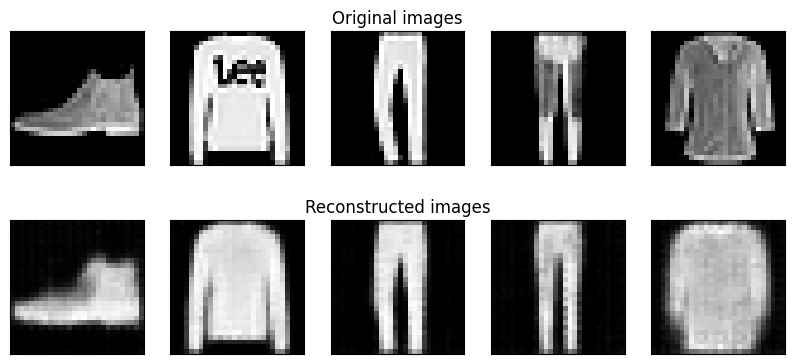

	 partial train loss (single batch): 0.020463
	 partial train loss (single batch): 0.020357
	 partial train loss (single batch): 0.021083
	 partial train loss (single batch): 0.019379
	 partial train loss (single batch): 0.020608
	 partial train loss (single batch): 0.020021
	 partial train loss (single batch): 0.022218
	 partial train loss (single batch): 0.019315


	 partial train loss (single batch): 0.020348
	 partial train loss (single batch): 0.019495
	 partial train loss (single batch): 0.020664
	 partial train loss (single batch): 0.018861
	 partial train loss (single batch): 0.020142


	 partial train loss (single batch): 0.019959
	 partial train loss (single batch): 0.020771
	 partial train loss (single batch): 0.020244
	 partial train loss (single batch): 0.020367
	 partial train loss (single batch): 0.020966
	 partial train loss (single batch): 0.019550
	 partial train loss (single batch): 0.021071
	 partial train loss (single batch): 0.019646


	 partial train loss (single batch): 0.019121
	 partial train loss (single batch): 0.021170
	 partial train loss (single batch): 0.021384
	 partial train loss (single batch): 0.020380
	 partial train loss (single batch): 0.019970
	 partial train loss (single batch): 0.020947


	 partial train loss (single batch): 0.020198
	 partial train loss (single batch): 0.019349
	 partial train loss (single batch): 0.018686
	 partial train loss (single batch): 0.019344
	 partial train loss (single batch): 0.019243
	 partial train loss (single batch): 0.019931
	 partial train loss (single batch): 0.021209
	 partial train loss (single batch): 0.020416


	 partial train loss (single batch): 0.019959
	 partial train loss (single batch): 0.019584
	 partial train loss (single batch): 0.019766
	 partial train loss (single batch): 0.019178
	 partial train loss (single batch): 0.020105


... (19 outputs left out)

	 partial train loss (single batch): 0.018755
	 partial train loss (single batch): 0.019503
	 partial train loss (single batch): 0.019668
	 partial train loss (single batch): 0.021087


	 partial train loss (single batch): 0.018505
	 partial train loss (single batch): 0.020502
	 partial train loss (single batch): 0.021430
	 partial train loss (single batch): 0.019515
	 partial train loss (single batch): 0.018047
	 partial train loss (single batch): 0.019820
	 partial train loss (single batch): 0.020571
	 partial train loss (single batch): 0.018909
	 partial train loss (single batch): 0.020629


	 partial train loss (single batch): 0.018146



 EPOCH 12/30 	 train loss 0.020 	 val loss 0.020


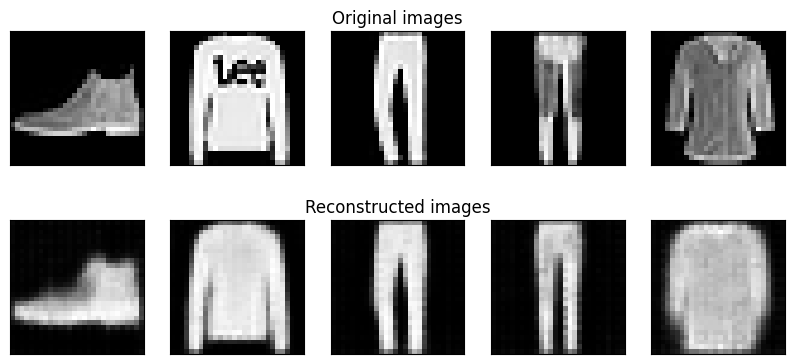

	 partial train loss (single batch): 0.020320
	 partial train loss (single batch): 0.020213
	 partial train loss (single batch): 0.020939
	 partial train loss (single batch): 0.019204
	 partial train loss (single batch): 0.020462
	 partial train loss (single batch): 0.019856
	 partial train loss (single batch): 0.022065
	 partial train loss (single batch): 0.019163


	 partial train loss (single batch): 0.020201
	 partial train loss (single batch): 0.019374
	 partial train loss (single batch): 0.020496
	 partial train loss (single batch): 0.018729
	 partial train loss (single batch): 0.020030


	 partial train loss (single batch): 0.019817
	 partial train loss (single batch): 0.020633
	 partial train loss (single batch): 0.020127
	 partial train loss (single batch): 0.020264
	 partial train loss (single batch): 0.020836
	 partial train loss (single batch): 0.019435
	 partial train loss (single batch): 0.020920
	 partial train loss (single batch): 0.019515


	 partial train loss (single batch): 0.018978
	 partial train loss (single batch): 0.021032
	 partial train loss (single batch): 0.021309
	 partial train loss (single batch): 0.020245
	 partial train loss (single batch): 0.019880


	 partial train loss (single batch): 0.020810
	 partial train loss (single batch): 0.020102
	 partial train loss (single batch): 0.019215
	 partial train loss (single batch): 0.018575
	 partial train loss (single batch): 0.019203
	 partial train loss (single batch): 0.019120
	 partial train loss (single batch): 0.019847
	 partial train loss (single batch): 0.021083


	 partial train loss (single batch): 0.020325
	 partial train loss (single batch): 0.019802
	 partial train loss (single batch): 0.019508
	 partial train loss (single batch): 0.019640
	 partial train loss (single batch): 0.019019


... (20 outputs left out)

	 partial train loss (single batch): 0.018473
	 partial train loss (single batch): 0.018674
	 partial train loss (single batch): 0.019396
	 partial train loss (single batch): 0.019530
	 partial train loss (single batch): 0.020959
	 partial train loss (single batch): 0.018387
	 partial train loss (single batch): 0.020360
	 partial train loss (single batch): 0.021322


	 partial train loss (single batch): 0.019365
	 partial train loss (single batch): 0.017911
	 partial train loss (single batch): 0.019689
	 partial train loss (single batch): 0.020444
	 partial train loss (single batch): 0.018812
	 partial train loss (single batch): 0.020505


	 partial train loss (single batch): 0.018029



 EPOCH 13/30 	 train loss 0.020 	 val loss 0.020


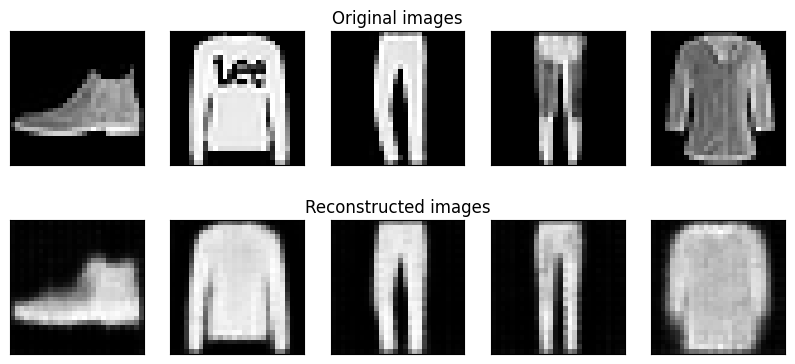

	 partial train loss (single batch): 0.020121
	 partial train loss (single batch): 0.020051
	 partial train loss (single batch): 0.020806
	 partial train loss (single batch): 0.019049
	 partial train loss (single batch): 0.020338
	 partial train loss (single batch): 0.019720
	 partial train loss (single batch): 0.021903
	 partial train loss (single batch): 0.019047


	 partial train loss (single batch): 0.020080
	 partial train loss (single batch): 0.019242
	 partial train loss (single batch): 0.020394
	 partial train loss (single batch): 0.018576
	 partial train loss (single batch): 0.019904
	 partial train loss (single batch): 0.019690


	 partial train loss (single batch): 0.020523
	 partial train loss (single batch): 0.020012
	 partial train loss (single batch): 0.020163
	 partial train loss (single batch): 0.020668
	 partial train loss (single batch): 0.019307
	 partial train loss (single batch): 0.020837
	 partial train loss (single batch): 0.019440


	 partial train loss (single batch): 0.018862
	 partial train loss (single batch): 0.020914
	 partial train loss (single batch): 0.021147
	 partial train loss (single batch): 0.020144
	 partial train loss (single batch): 0.019765
	 partial train loss (single batch): 0.020748
	 partial train loss (single batch): 0.019949


	 partial train loss (single batch): 0.019111
	 partial train loss (single batch): 0.018488
	 partial train loss (single batch): 0.019095
	 partial train loss (single batch): 0.019016
	 partial train loss (single batch): 0.019718
	 partial train loss (single batch): 0.020980
	 partial train loss (single batch): 0.020227


	 partial train loss (single batch): 0.019688
	 partial train loss (single batch): 0.019396
	 partial train loss (single batch): 0.019529
	 partial train loss (single batch): 0.018961
	 partial train loss (single batch): 0.019889
	 partial train loss (single batch): 0.019411
	 partial train loss (single batch): 0.019147


... (19 outputs left out)

	 partial train loss (single batch): 0.020472
	 partial train loss (single batch): 0.019544
	 partial train loss (single batch): 0.019786
	 partial train loss (single batch): 0.020635
	 partial train loss (single batch): 0.019895
	 partial train loss (single batch): 0.018372
	 partial train loss (single batch): 0.018574
	 partial train loss (single batch): 0.019286


	 partial train loss (single batch): 0.019440
	 partial train loss (single batch): 0.020873
	 partial train loss (single batch): 0.018279
	 partial train loss (single batch): 0.020270
	 partial train loss (single batch): 0.021210


	 partial train loss (single batch): 0.019210
	 partial train loss (single batch): 0.017803
	 partial train loss (single batch): 0.019583
	 partial train loss (single batch): 0.020324
	 partial train loss (single batch): 0.018721
	 partial train loss (single batch): 0.020384
	 partial train loss (single batch): 0.017940



 EPOCH 14/30 	 train loss 0.020 	 val loss 0.020


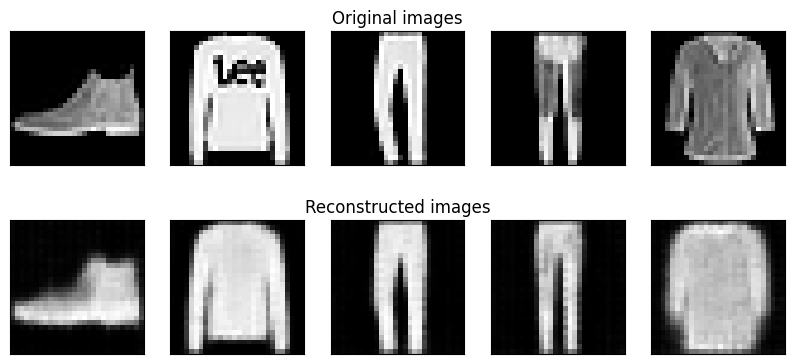

	 partial train loss (single batch): 0.020046
	 partial train loss (single batch): 0.019930
	 partial train loss (single batch): 0.020723
	 partial train loss (single batch): 0.018967
	 partial train loss (single batch): 0.020247
	 partial train loss (single batch): 0.019637
	 partial train loss (single batch): 0.021785
	 partial train loss (single batch): 0.018911


	 partial train loss (single batch): 0.019969
	 partial train loss (single batch): 0.019124
	 partial train loss (single batch): 0.020320
	 partial train loss (single batch): 0.018449
	 partial train loss (single batch): 0.019787


	 partial train loss (single batch): 0.019592
	 partial train loss (single batch): 0.020365
	 partial train loss (single batch): 0.019895
	 partial train loss (single batch): 0.020077
	 partial train loss (single batch): 0.020536
	 partial train loss (single batch): 0.019172
	 partial train loss (single batch): 0.020722
	 partial train loss (single batch): 0.019339


	 partial train loss (single batch): 0.018745
	 partial train loss (single batch): 0.020762
	 partial train loss (single batch): 0.021016
	 partial train loss (single batch): 0.020045
	 partial train loss (single batch): 0.019650


	 partial train loss (single batch): 0.020638
	 partial train loss (single batch): 0.019832
	 partial train loss (single batch): 0.018994
	 partial train loss (single batch): 0.018402
	 partial train loss (single batch): 0.018990
	 partial train loss (single batch): 0.018914
	 partial train loss (single batch): 0.019639
	 partial train loss (single batch): 0.020885


	 partial train loss (single batch): 0.020139
	 partial train loss (single batch): 0.019590
	 partial train loss (single batch): 0.019361
	 partial train loss (single batch): 0.019425
	 partial train loss (single batch): 0.018859
	 partial train loss (single batch): 0.019800


... (20 outputs left out)

	 partial train loss (single batch): 0.020512
	 partial train loss (single batch): 0.019845
	 partial train loss (single batch): 0.018293
	 partial train loss (single batch): 0.018449
	 partial train loss (single batch): 0.019189
	 partial train loss (single batch): 0.019373


	 partial train loss (single batch): 0.020761
	 partial train loss (single batch): 0.018191
	 partial train loss (single batch): 0.020198
	 partial train loss (single batch): 0.021121
	 partial train loss (single batch): 0.019118
	 partial train loss (single batch): 0.017720
	 partial train loss (single batch): 0.019496


	 partial train loss (single batch): 0.020220
	 partial train loss (single batch): 0.018691
	 partial train loss (single batch): 0.020267
	 partial train loss (single batch): 0.017861



 EPOCH 15/30 	 train loss 0.020 	 val loss 0.020


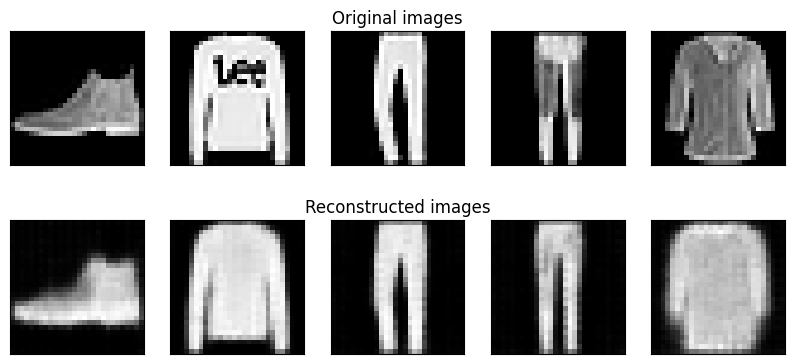

	 partial train loss (single batch): 0.019928
	 partial train loss (single batch): 0.019852
	 partial train loss (single batch): 0.020643
	 partial train loss (single batch): 0.018904
	 partial train loss (single batch): 0.020170
	 partial train loss (single batch): 0.019547
	 partial train loss (single batch): 0.021685


	 partial train loss (single batch): 0.018819
	 partial train loss (single batch): 0.019888
	 partial train loss (single batch): 0.019026
	 partial train loss (single batch): 0.020253
	 partial train loss (single batch): 0.018342
	 partial train loss (single batch): 0.019708


	 partial train loss (single batch): 0.019476
	 partial train loss (single batch): 0.020269
	 partial train loss (single batch): 0.019811
	 partial train loss (single batch): 0.020018
	 partial train loss (single batch): 0.020444
	 partial train loss (single batch): 0.019083
	 partial train loss (single batch): 0.020657


	 partial train loss (single batch): 0.019190
	 partial train loss (single batch): 0.018666
	 partial train loss (single batch): 0.020623
	 partial train loss (single batch): 0.020901
	 partial train loss (single batch): 0.019960
	 partial train loss (single batch): 0.019556


	 partial train loss (single batch): 0.020533
	 partial train loss (single batch): 0.019714
	 partial train loss (single batch): 0.018883
	 partial train loss (single batch): 0.018330
	 partial train loss (single batch): 0.018909
	 partial train loss (single batch): 0.018833
	 partial train loss (single batch): 0.019548


	 partial train loss (single batch): 0.020787
	 partial train loss (single batch): 0.020039
	 partial train loss (single batch): 0.019482
	 partial train loss (single batch): 0.019278
	 partial train loss (single batch): 0.019310
	 partial train loss (single batch): 0.018783
	 partial train loss (single batch): 0.019715


... (23 outputs left out)

	 partial train loss (single batch): 0.020443
	 partial train loss (single batch): 0.019797
	 partial train loss (single batch): 0.018198
	 partial train loss (single batch): 0.018396
	 partial train loss (single batch): 0.019142
	 partial train loss (single batch): 0.019267
	 partial train loss (single batch): 0.020697
	 partial train loss (single batch): 0.018107
	 partial train loss (single batch): 0.020095
	 partial train loss (single batch): 0.021079


	 partial train loss (single batch): 0.019032
	 partial train loss (single batch): 0.017609
	 partial train loss (single batch): 0.019414


	 partial train loss (single batch): 0.020154
	 partial train loss (single batch): 0.018631
	 partial train loss (single batch): 0.020200
	 partial train loss (single batch): 0.017745



 EPOCH 16/30 	 train loss 0.020 	 val loss 0.020


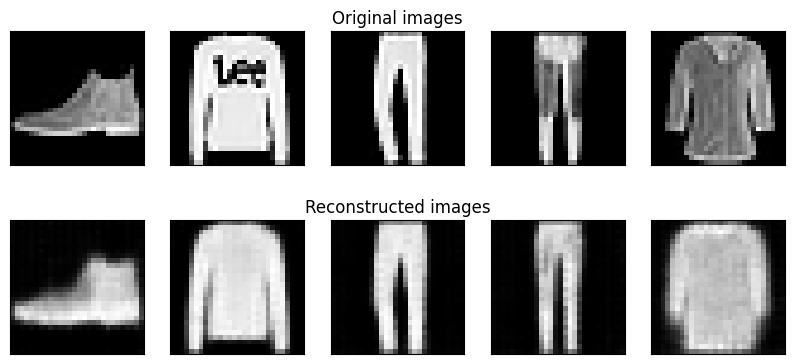

	 partial train loss (single batch): 0.019823
	 partial train loss (single batch): 0.019739
	 partial train loss (single batch): 0.020580
	 partial train loss (single batch): 0.018812
	 partial train loss (single batch): 0.020072
	 partial train loss (single batch): 0.019450
	 partial train loss (single batch): 0.021588


	 partial train loss (single batch): 0.018735
	 partial train loss (single batch): 0.019823
	 partial train loss (single batch): 0.018920
	 partial train loss (single batch): 0.020153
	 partial train loss (single batch): 0.018233
	 partial train loss (single batch): 0.019620


	 partial train loss (single batch): 0.019375
	 partial train loss (single batch): 0.020156
	 partial train loss (single batch): 0.019702
	 partial train loss (single batch): 0.019901
	 partial train loss (single batch): 0.020374
	 partial train loss (single batch): 0.018982
	 partial train loss (single batch): 0.020567


	 partial train loss (single batch): 0.019065
	 partial train loss (single batch): 0.018588
	 partial train loss (single batch): 0.020523
	 partial train loss (single batch): 0.020831
	 partial train loss (single batch): 0.019861
	 partial train loss (single batch): 0.019456


	 partial train loss (single batch): 0.020450
	 partial train loss (single batch): 0.019625
	 partial train loss (single batch): 0.018769
	 partial train loss (single batch): 0.018252
	 partial train loss (single batch): 0.018822
	 partial train loss (single batch): 0.018744
	 partial train loss (single batch): 0.019451


	 partial train loss (single batch): 0.020721
	 partial train loss (single batch): 0.019963
	 partial train loss (single batch): 0.019376
	 partial train loss (single batch): 0.019207
	 partial train loss (single batch): 0.019213
	 partial train loss (single batch): 0.018706


... (20 outputs left out)

	 partial train loss (single batch): 0.019519
	 partial train loss (single batch): 0.020384
	 partial train loss (single batch): 0.019742
	 partial train loss (single batch): 0.018125
	 partial train loss (single batch): 0.018293
	 partial train loss (single batch): 0.019072
	 partial train loss (single batch): 0.019198
	 partial train loss (single batch): 0.020627
	 partial train loss (single batch): 0.018006


	 partial train loss (single batch): 0.020031
	 partial train loss (single batch): 0.020984
	 partial train loss (single batch): 0.018949
	 partial train loss (single batch): 0.017521


	 partial train loss (single batch): 0.019333
	 partial train loss (single batch): 0.020076
	 partial train loss (single batch): 0.018597
	 partial train loss (single batch): 0.020127
	 partial train loss (single batch): 0.017656



 EPOCH 17/30 	 train loss 0.020 	 val loss 0.020


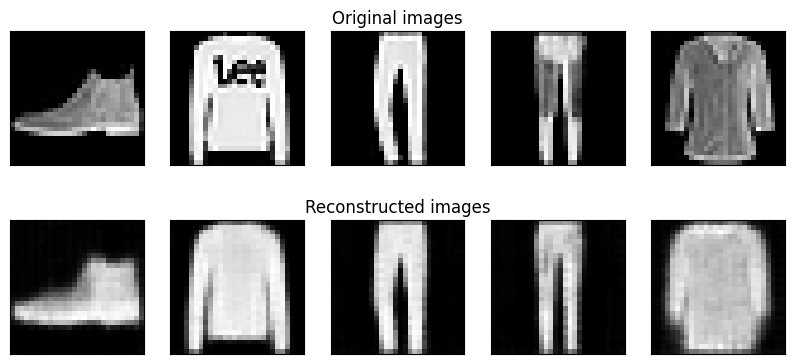

	 partial train loss (single batch): 0.019752
	 partial train loss (single batch): 0.019678
	 partial train loss (single batch): 0.020517
	 partial train loss (single batch): 0.018747
	 partial train loss (single batch): 0.020007
	 partial train loss (single batch): 0.019398
	 partial train loss (single batch): 0.021523
	 partial train loss (single batch): 0.018659


	 partial train loss (single batch): 0.019761
	 partial train loss (single batch): 0.018886
	 partial train loss (single batch): 0.020114
	 partial train loss (single batch): 0.018150
	 partial train loss (single batch): 0.019565


	 partial train loss (single batch): 0.019325
	 partial train loss (single batch): 0.020058
	 partial train loss (single batch): 0.019649
	 partial train loss (single batch): 0.019809
	 partial train loss (single batch): 0.020341
	 partial train loss (single batch): 0.018893
	 partial train loss (single batch): 0.020514
	 partial train loss (single batch): 0.018973
	 partial train loss (single batch): 0.018538


	 partial train loss (single batch): 0.020442
	 partial train loss (single batch): 0.020729
	 partial train loss (single batch): 0.019803
	 partial train loss (single batch): 0.019396
	 partial train loss (single batch): 0.020401


	 partial train loss (single batch): 0.019518
	 partial train loss (single batch): 0.018671
	 partial train loss (single batch): 0.018191
	 partial train loss (single batch): 0.018737
	 partial train loss (single batch): 0.018671
	 partial train loss (single batch): 0.019346
	 partial train loss (single batch): 0.020644
	 partial train loss (single batch): 0.019874
	 partial train loss (single batch): 0.019286


	 partial train loss (single batch): 0.019150
	 partial train loss (single batch): 0.019138
	 partial train loss (single batch): 0.018626
	 partial train loss (single batch): 0.019601
	 partial train loss (single batch): 0.019098


... (19 outputs left out)

	 partial train loss (single batch): 0.019442
	 partial train loss (single batch): 0.020278
	 partial train loss (single batch): 0.019646
	 partial train loss (single batch): 0.018056
	 partial train loss (single batch): 0.018270


	 partial train loss (single batch): 0.019019
	 partial train loss (single batch): 0.019156
	 partial train loss (single batch): 0.020547
	 partial train loss (single batch): 0.017939
	 partial train loss (single batch): 0.019976
	 partial train loss (single batch): 0.020932
	 partial train loss (single batch): 0.018866
	 partial train loss (single batch): 0.017475
	 partial train loss (single batch): 0.019279


	 partial train loss (single batch): 0.020038
	 partial train loss (single batch): 0.018543
	 partial train loss (single batch): 0.020053
	 partial train loss (single batch): 0.017598



 EPOCH 18/30 	 train loss 0.019 	 val loss 0.019


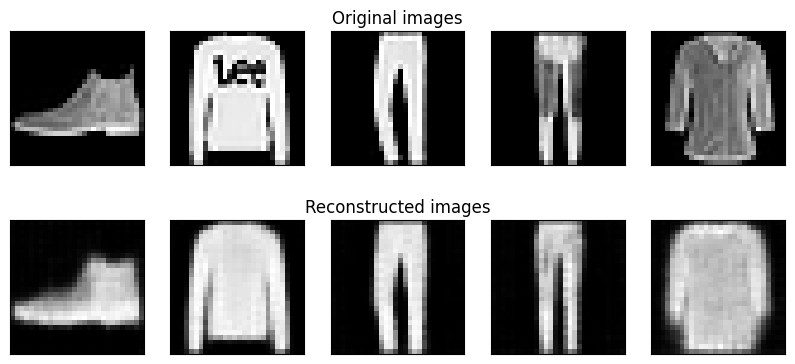

	 partial train loss (single batch): 0.019672
	 partial train loss (single batch): 0.019611
	 partial train loss (single batch): 0.020464
	 partial train loss (single batch): 0.018692
	 partial train loss (single batch): 0.019927
	 partial train loss (single batch): 0.019344
	 partial train loss (single batch): 0.021481
	 partial train loss (single batch): 0.018584


	 partial train loss (single batch): 0.019707
	 partial train loss (single batch): 0.018788
	 partial train loss (single batch): 0.020066
	 partial train loss (single batch): 0.018080
	 partial train loss (single batch): 0.019528
	 partial train loss (single batch): 0.019240


	 partial train loss (single batch): 0.019979
	 partial train loss (single batch): 0.019567
	 partial train loss (single batch): 0.019739
	 partial train loss (single batch): 0.020274
	 partial train loss (single batch): 0.018800
	 partial train loss (single batch): 0.020456
	 partial train loss (single batch): 0.018895


	 partial train loss (single batch): 0.018472
	 partial train loss (single batch): 0.020357
	 partial train loss (single batch): 0.020675
	 partial train loss (single batch): 0.019755
	 partial train loss (single batch): 0.019332
	 partial train loss (single batch): 0.020324


	 partial train loss (single batch): 0.019444
	 partial train loss (single batch): 0.018605
	 partial train loss (single batch): 0.018123
	 partial train loss (single batch): 0.018665
	 partial train loss (single batch): 0.018583
	 partial train loss (single batch): 0.019263
	 partial train loss (single batch): 0.020558
	 partial train loss (single batch): 0.019818


	 partial train loss (single batch): 0.019253
	 partial train loss (single batch): 0.019087
	 partial train loss (single batch): 0.019073
	 partial train loss (single batch): 0.018568
	 partial train loss (single batch): 0.019577
	 partial train loss (single batch): 0.019025


... (19 outputs left out)

	 partial train loss (single batch): 0.019257
	 partial train loss (single batch): 0.019385
	 partial train loss (single batch): 0.020246
	 partial train loss (single batch): 0.019603
	 partial train loss (single batch): 0.018007
	 partial train loss (single batch): 0.018177


	 partial train loss (single batch): 0.019003
	 partial train loss (single batch): 0.019105
	 partial train loss (single batch): 0.020504
	 partial train loss (single batch): 0.017878
	 partial train loss (single batch): 0.019929
	 partial train loss (single batch): 0.020853
	 partial train loss (single batch): 0.018783


	 partial train loss (single batch): 0.017446
	 partial train loss (single batch): 0.019211
	 partial train loss (single batch): 0.019941
	 partial train loss (single batch): 0.018503
	 partial train loss (single batch): 0.019934
	 partial train loss (single batch): 0.017542



 EPOCH 19/30 	 train loss 0.019 	 val loss 0.019


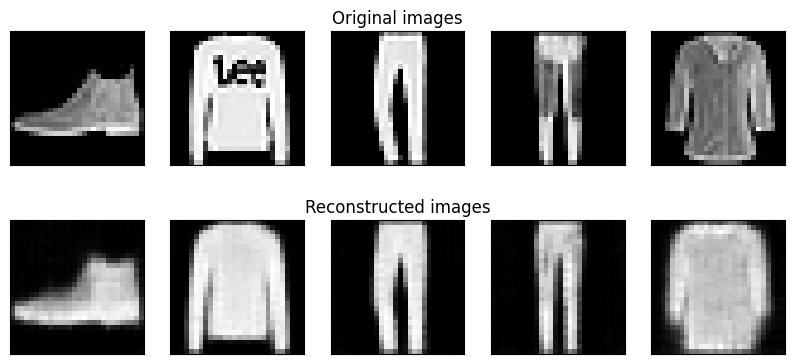

	 partial train loss (single batch): 0.019605
	 partial train loss (single batch): 0.019578
	 partial train loss (single batch): 0.020383
	 partial train loss (single batch): 0.018614
	 partial train loss (single batch): 0.019888
	 partial train loss (single batch): 0.019227
	 partial train loss (single batch): 0.021405
	 partial train loss (single batch): 0.018544


	 partial train loss (single batch): 0.019612
	 partial train loss (single batch): 0.018700
	 partial train loss (single batch): 0.019981
	 partial train loss (single batch): 0.018010
	 partial train loss (single batch): 0.019416


	 partial train loss (single batch): 0.019191
	 partial train loss (single batch): 0.019897
	 partial train loss (single batch): 0.019527
	 partial train loss (single batch): 0.019688
	 partial train loss (single batch): 0.020201
	 partial train loss (single batch): 0.018738
	 partial train loss (single batch): 0.020379
	 partial train loss (single batch): 0.018839


	 partial train loss (single batch): 0.018417
	 partial train loss (single batch): 0.020277
	 partial train loss (single batch): 0.020596
	 partial train loss (single batch): 0.019715
	 partial train loss (single batch): 0.019272


	 partial train loss (single batch): 0.020259
	 partial train loss (single batch): 0.019391
	 partial train loss (single batch): 0.018521
	 partial train loss (single batch): 0.018085
	 partial train loss (single batch): 0.018621
	 partial train loss (single batch): 0.018554
	 partial train loss (single batch): 0.019188
	 partial train loss (single batch): 0.020485


	 partial train loss (single batch): 0.019759
	 partial train loss (single batch): 0.019189
	 partial train loss (single batch): 0.019051
	 partial train loss (single batch): 0.019034
	 partial train loss (single batch): 0.018518


... (20 outputs left out)

	 partial train loss (single batch): 0.019296
	 partial train loss (single batch): 0.020181
	 partial train loss (single batch): 0.019545
	 partial train loss (single batch): 0.017911
	 partial train loss (single batch): 0.018102
	 partial train loss (single batch): 0.018929
	 partial train loss (single batch): 0.019045
	 partial train loss (single batch): 0.020425


	 partial train loss (single batch): 0.017776
	 partial train loss (single batch): 0.019863
	 partial train loss (single batch): 0.020781
	 partial train loss (single batch): 0.018709


	 partial train loss (single batch): 0.017357
	 partial train loss (single batch): 0.019179
	 partial train loss (single batch): 0.019898
	 partial train loss (single batch): 0.018453
	 partial train loss (single batch): 0.019891
	 partial train loss (single batch): 0.017489



 EPOCH 20/30 	 train loss 0.019 	 val loss 0.019


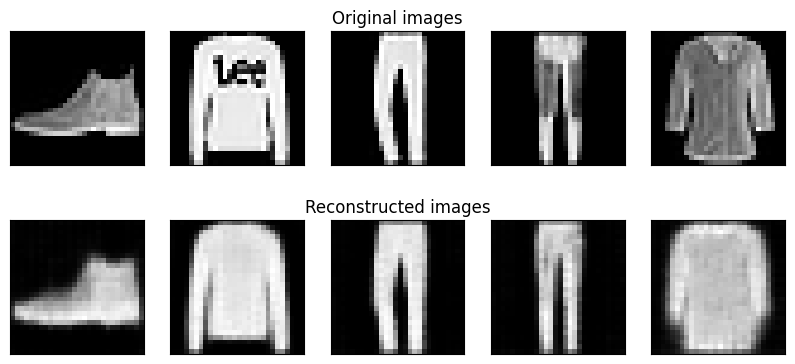

	 partial train loss (single batch): 0.019572
	 partial train loss (single batch): 0.019518
	 partial train loss (single batch): 0.020360
	 partial train loss (single batch): 0.018560
	 partial train loss (single batch): 0.019813
	 partial train loss (single batch): 0.019190
	 partial train loss (single batch): 0.021373


	 partial train loss (single batch): 0.018479
	 partial train loss (single batch): 0.019548
	 partial train loss (single batch): 0.018637
	 partial train loss (single batch): 0.019914
	 partial train loss (single batch): 0.017969
	 partial train loss (single batch): 0.019373


	 partial train loss (single batch): 0.019167
	 partial train loss (single batch): 0.019828
	 partial train loss (single batch): 0.019476
	 partial train loss (single batch): 0.019645
	 partial train loss (single batch): 0.020145
	 partial train loss (single batch): 0.018698
	 partial train loss (single batch): 0.020309


	 partial train loss (single batch): 0.018779
	 partial train loss (single batch): 0.018385
	 partial train loss (single batch): 0.020200
	 partial train loss (single batch): 0.020522
	 partial train loss (single batch): 0.019677
	 partial train loss (single batch): 0.019159


	 partial train loss (single batch): 0.020184
	 partial train loss (single batch): 0.019373
	 partial train loss (single batch): 0.018462
	 partial train loss (single batch): 0.017987
	 partial train loss (single batch): 0.018583
	 partial train loss (single batch): 0.018470
	 partial train loss (single batch): 0.019145
	 partial train loss (single batch): 0.020433


	 partial train loss (single batch): 0.019686
	 partial train loss (single batch): 0.019133
	 partial train loss (single batch): 0.019013
	 partial train loss (single batch): 0.018963
	 partial train loss (single batch): 0.018462
	 partial train loss (single batch): 0.019475


... (20 outputs left out)

	 partial train loss (single batch): 0.019144
	 partial train loss (single batch): 0.019267
	 partial train loss (single batch): 0.020117
	 partial train loss (single batch): 0.019465
	 partial train loss (single batch): 0.017842
	 partial train loss (single batch): 0.018049


	 partial train loss (single batch): 0.018859
	 partial train loss (single batch): 0.018977
	 partial train loss (single batch): 0.020359
	 partial train loss (single batch): 0.017701
	 partial train loss (single batch): 0.019820
	 partial train loss (single batch): 0.020739
	 partial train loss (single batch): 0.018670


	 partial train loss (single batch): 0.017325
	 partial train loss (single batch): 0.019094
	 partial train loss (single batch): 0.019843
	 partial train loss (single batch): 0.018424
	 partial train loss (single batch): 0.019802
	 partial train loss (single batch): 0.017394



 EPOCH 21/30 	 train loss 0.019 	 val loss 0.019


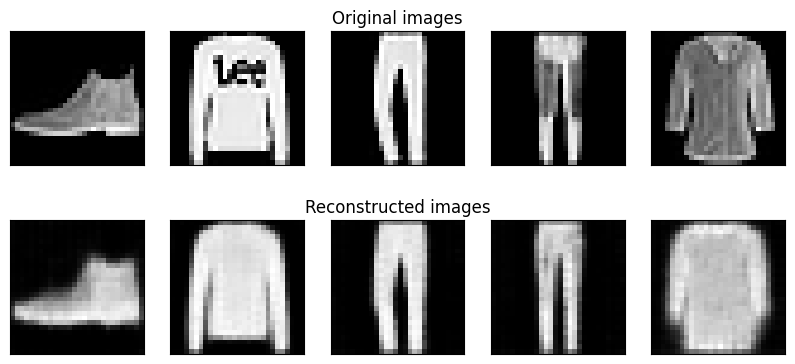

	 partial train loss (single batch): 0.019481
	 partial train loss (single batch): 0.019472
	 partial train loss (single batch): 0.020281
	 partial train loss (single batch): 0.018509
	 partial train loss (single batch): 0.019742
	 partial train loss (single batch): 0.019130


	 partial train loss (single batch): 0.021311
	 partial train loss (single batch): 0.018424
	 partial train loss (single batch): 0.019494
	 partial train loss (single batch): 0.018606
	 partial train loss (single batch): 0.019884
	 partial train loss (single batch): 0.017900
	 partial train loss (single batch): 0.019296


	 partial train loss (single batch): 0.019103
	 partial train loss (single batch): 0.019793
	 partial train loss (single batch): 0.019418
	 partial train loss (single batch): 0.019632
	 partial train loss (single batch): 0.020074
	 partial train loss (single batch): 0.018669


	 partial train loss (single batch): 0.020241
	 partial train loss (single batch): 0.018734
	 partial train loss (single batch): 0.018313
	 partial train loss (single batch): 0.020135
	 partial train loss (single batch): 0.020479
	 partial train loss (single batch): 0.019626
	 partial train loss (single batch): 0.019124


	 partial train loss (single batch): 0.020164
	 partial train loss (single batch): 0.019239
	 partial train loss (single batch): 0.018405
	 partial train loss (single batch): 0.017946
	 partial train loss (single batch): 0.018519
	 partial train loss (single batch): 0.018414


	 partial train loss (single batch): 0.019083
	 partial train loss (single batch): 0.020364
	 partial train loss (single batch): 0.019615
	 partial train loss (single batch): 0.019061
	 partial train loss (single batch): 0.018961
	 partial train loss (single batch): 0.018922


... (20 outputs left out)

	 partial train loss (single batch): 0.019408
	 partial train loss (single batch): 0.018157
	 partial train loss (single batch): 0.019895
	 partial train loss (single batch): 0.019111
	 partial train loss (single batch): 0.019219
	 partial train loss (single batch): 0.020047
	 partial train loss (single batch): 0.019425
	 partial train loss (single batch): 0.017753


	 partial train loss (single batch): 0.018014
	 partial train loss (single batch): 0.018822
	 partial train loss (single batch): 0.018941
	 partial train loss (single batch): 0.020314
	 partial train loss (single batch): 0.017682
	 partial train loss (single batch): 0.019763


	 partial train loss (single batch): 0.020685
	 partial train loss (single batch): 0.018605
	 partial train loss (single batch): 0.017270
	 partial train loss (single batch): 0.019083
	 partial train loss (single batch): 0.019790
	 partial train loss (single batch): 0.018389
	 partial train loss (single batch): 0.019782
	 partial train loss (single batch): 0.017375



 EPOCH 22/30 	 train loss 0.019 	 val loss 0.019


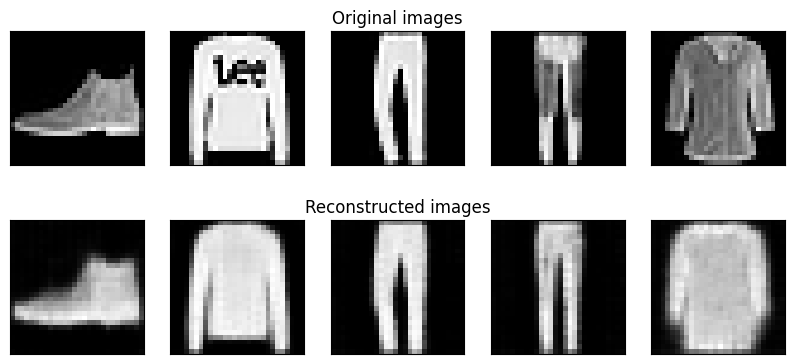

	 partial train loss (single batch): 0.019415
	 partial train loss (single batch): 0.019422
	 partial train loss (single batch): 0.020278
	 partial train loss (single batch): 0.018451
	 partial train loss (single batch): 0.019694
	 partial train loss (single batch): 0.019104
	 partial train loss (single batch): 0.021273


	 partial train loss (single batch): 0.018383
	 partial train loss (single batch): 0.019452
	 partial train loss (single batch): 0.018561
	 partial train loss (single batch): 0.019830
	 partial train loss (single batch): 0.017867
	 partial train loss (single batch): 0.019262


	 partial train loss (single batch): 0.019086
	 partial train loss (single batch): 0.019732
	 partial train loss (single batch): 0.019392
	 partial train loss (single batch): 0.019600
	 partial train loss (single batch): 0.020025
	 partial train loss (single batch): 0.018627
	 partial train loss (single batch): 0.020213


	 partial train loss (single batch): 0.018672
	 partial train loss (single batch): 0.018297
	 partial train loss (single batch): 0.020089
	 partial train loss (single batch): 0.020421
	 partial train loss (single batch): 0.019579
	 partial train loss (single batch): 0.019093


	 partial train loss (single batch): 0.020134
	 partial train loss (single batch): 0.019194
	 partial train loss (single batch): 0.018318
	 partial train loss (single batch): 0.017889
	 partial train loss (single batch): 0.018487
	 partial train loss (single batch): 0.018354
	 partial train loss (single batch): 0.019021


	 partial train loss (single batch): 0.020325
	 partial train loss (single batch): 0.019583
	 partial train loss (single batch): 0.019051
	 partial train loss (single batch): 0.018906
	 partial train loss (single batch): 0.018874


... (20 outputs left out)

	 partial train loss (single batch): 0.019832
	 partial train loss (single batch): 0.019065
	 partial train loss (single batch): 0.019173
	 partial train loss (single batch): 0.019993
	 partial train loss (single batch): 0.019382
	 partial train loss (single batch): 0.017699
	 partial train loss (single batch): 0.017963
	 partial train loss (single batch): 0.018762
	 partial train loss (single batch): 0.018906


	 partial train loss (single batch): 0.020251
	 partial train loss (single batch): 0.017609
	 partial train loss (single batch): 0.019722
	 partial train loss (single batch): 0.020635


	 partial train loss (single batch): 0.018538
	 partial train loss (single batch): 0.017217
	 partial train loss (single batch): 0.019061
	 partial train loss (single batch): 0.019742
	 partial train loss (single batch): 0.018359
	 partial train loss (single batch): 0.019721
	 partial train loss (single batch): 0.017348



 EPOCH 23/30 	 train loss 0.019 	 val loss 0.019


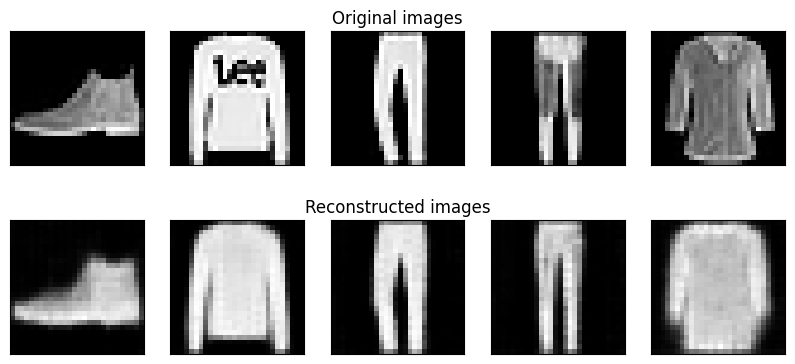

	 partial train loss (single batch): 0.019361
	 partial train loss (single batch): 0.019380
	 partial train loss (single batch): 0.020235
	 partial train loss (single batch): 0.018421
	 partial train loss (single batch): 0.019665
	 partial train loss (single batch): 0.019091
	 partial train loss (single batch): 0.021217


	 partial train loss (single batch): 0.018366
	 partial train loss (single batch): 0.019421
	 partial train loss (single batch): 0.018515
	 partial train loss (single batch): 0.019817
	 partial train loss (single batch): 0.017844
	 partial train loss (single batch): 0.019256


	 partial train loss (single batch): 0.019043
	 partial train loss (single batch): 0.019711
	 partial train loss (single batch): 0.019392
	 partial train loss (single batch): 0.019515
	 partial train loss (single batch): 0.020024
	 partial train loss (single batch): 0.018620
	 partial train loss (single batch): 0.020236


	 partial train loss (single batch): 0.018626
	 partial train loss (single batch): 0.018301
	 partial train loss (single batch): 0.020009
	 partial train loss (single batch): 0.020401
	 partial train loss (single batch): 0.019606
	 partial train loss (single batch): 0.019041


	 partial train loss (single batch): 0.020094
	 partial train loss (single batch): 0.019124
	 partial train loss (single batch): 0.018273
	 partial train loss (single batch): 0.017847
	 partial train loss (single batch): 0.018434
	 partial train loss (single batch): 0.018332
	 partial train loss (single batch): 0.018973


	 partial train loss (single batch): 0.020285
	 partial train loss (single batch): 0.019548
	 partial train loss (single batch): 0.019041
	 partial train loss (single batch): 0.018871
	 partial train loss (single batch): 0.018840
	 partial train loss (single batch): 0.018336


... (20 outputs left out)

	 partial train loss (single batch): 0.019128
	 partial train loss (single batch): 0.019923
	 partial train loss (single batch): 0.019322
	 partial train loss (single batch): 0.017660
	 partial train loss (single batch): 0.017887
	 partial train loss (single batch): 0.018709
	 partial train loss (single batch): 0.018851


	 partial train loss (single batch): 0.020195
	 partial train loss (single batch): 0.017542
	 partial train loss (single batch): 0.019674
	 partial train loss (single batch): 0.020586
	 partial train loss (single batch): 0.018499
	 partial train loss (single batch): 0.017145


	 partial train loss (single batch): 0.019005
	 partial train loss (single batch): 0.019690
	 partial train loss (single batch): 0.018298
	 partial train loss (single batch): 0.019729
	 partial train loss (single batch): 0.017299



 EPOCH 24/30 	 train loss 0.019 	 val loss 0.019


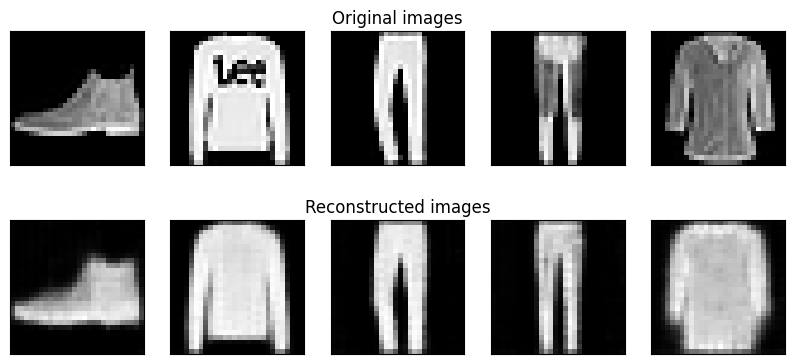

	 partial train loss (single batch): 0.019329
	 partial train loss (single batch): 0.019377
	 partial train loss (single batch): 0.020185
	 partial train loss (single batch): 0.018438
	 partial train loss (single batch): 0.019589
	 partial train loss (single batch): 0.019076
	 partial train loss (single batch): 0.021190
	 partial train loss (single batch): 0.018330
	 partial train loss (single batch): 0.019393
	 partial train loss (single batch): 0.018511
	 partial train loss (single batch): 0.019809
	 partial train loss (single batch): 0.017815


	 partial train loss (single batch): 0.019225
	 partial train loss (single batch): 0.019039
	 partial train loss (single batch): 0.019703
	 partial train loss (single batch): 0.019327
	 partial train loss (single batch): 0.019572
	 partial train loss (single batch): 0.019975
	 partial train loss (single batch): 0.018570
	 partial train loss (single batch): 0.020130
	 partial train loss (single batch): 0.018619
	 partial train loss (single batch): 0.018257
	 partial train loss (single batch): 0.020006
	 partial train loss (single batch): 0.020388
	 partial train loss (single batch): 0.019518


	 partial train loss (single batch): 0.019072
	 partial train loss (single batch): 0.020065
	 partial train loss (single batch): 0.019067
	 partial train loss (single batch): 0.018278
	 partial train loss (single batch): 0.017833
	 partial train loss (single batch): 0.018405
	 partial train loss (single batch): 0.018234
	 partial train loss (single batch): 0.018927
	 partial train loss (single batch): 0.020184
	 partial train loss (single batch): 0.019551
	 partial train loss (single batch): 0.018942
	 partial train loss (single batch): 0.018823
	 partial train loss (single batch): 0.018760


	 partial train loss (single batch): 0.018252
	 partial train loss (single batch): 0.019262
	 partial train loss (single batch): 0.018717
	 partial train loss (single batch): 0.018459
	 partial train loss (single batch): 0.019358
	 partial train loss (single batch): 0.017338
	 partial train loss (single batch): 0.018986
	 partial train loss (single batch): 0.020338
	 partial train loss (single batch): 0.018152
	 partial train loss (single batch): 0.019175
	 partial train loss (single batch): 0.019159
	 partial train loss (single batch): 0.020860
	 partial train loss (single batch): 0.019470


	 partial train loss (single batch): 0.019407
	 partial train loss (single batch): 0.020766
	 partial train loss (single batch): 0.019328
	 partial train loss (single batch): 0.019632
	 partial train loss (single batch): 0.017520
	 partial train loss (single batch): 0.020793
	 partial train loss (single batch): 0.018553
	 partial train loss (single batch): 0.018405
	 partial train loss (single batch): 0.020219
	 partial train loss (single batch): 0.019659
	 partial train loss (single batch): 0.019704
	 partial train loss (single batch): 0.018597
	 partial train loss (single batch): 0.019481


	 partial train loss (single batch): 0.017412
	 partial train loss (single batch): 0.018757
	 partial train loss (single batch): 0.019032
	 partial train loss (single batch): 0.018367
	 partial train loss (single batch): 0.019398
	 partial train loss (single batch): 0.018512
	 partial train loss (single batch): 0.020102
	 partial train loss (single batch): 0.018671
	 partial train loss (single batch): 0.018583
	 partial train loss (single batch): 0.019492
	 partial train loss (single batch): 0.019279
	 partial train loss (single batch): 0.019854
	 partial train loss (single batch): 0.018144


... (6 outputs left out)

	 partial train loss (single batch): 0.019565
	 partial train loss (single batch): 0.018112
	 partial train loss (single batch): 0.018047
	 partial train loss (single batch): 0.019432
	 partial train loss (single batch): 0.020088
	 partial train loss (single batch): 0.019909
	 partial train loss (single batch): 0.019082
	 partial train loss (single batch): 0.019643
	 partial train loss (single batch): 0.020003
	 partial train loss (single batch): 0.019160
	 partial train loss (single batch): 0.019852
	 partial train loss (single batch): 0.019377
	 partial train loss (single batch): 0.018027


	 partial train loss (single batch): 0.019753
	 partial train loss (single batch): 0.019022
	 partial train loss (single batch): 0.019128
	 partial train loss (single batch): 0.019904
	 partial train loss (single batch): 0.019306
	 partial train loss (single batch): 0.017622
	 partial train loss (single batch): 0.017862
	 partial train loss (single batch): 0.018718
	 partial train loss (single batch): 0.018788
	 partial train loss (single batch): 0.020151
	 partial train loss (single batch): 0.017541
	 partial train loss (single batch): 0.019623
	 partial train loss (single batch): 0.020549


	 partial train loss (single batch): 0.018463
	 partial train loss (single batch): 0.017148
	 partial train loss (single batch): 0.018966
	 partial train loss (single batch): 0.019664
	 partial train loss (single batch): 0.018331
	 partial train loss (single batch): 0.019706
	 partial train loss (single batch): 0.017233



 EPOCH 25/30 	 train loss 0.019 	 val loss 0.019


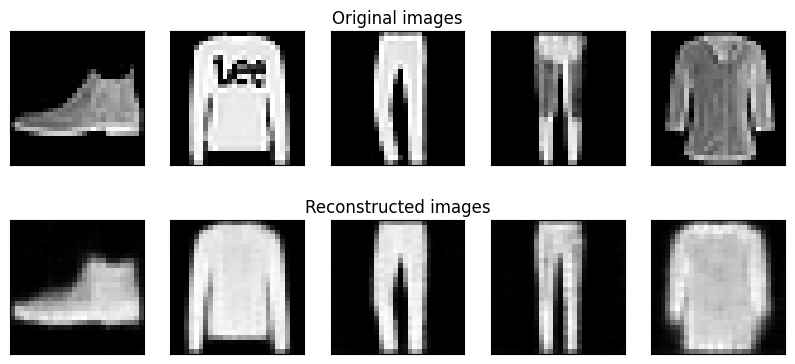

	 partial train loss (single batch): 0.019291
	 partial train loss (single batch): 0.019356
	 partial train loss (single batch): 0.020168
	 partial train loss (single batch): 0.018409
	 partial train loss (single batch): 0.019563
	 partial train loss (single batch): 0.019041
	 partial train loss (single batch): 0.021151


	 partial train loss (single batch): 0.018291
	 partial train loss (single batch): 0.019373
	 partial train loss (single batch): 0.018457
	 partial train loss (single batch): 0.019751
	 partial train loss (single batch): 0.017801
	 partial train loss (single batch): 0.019148


	 partial train loss (single batch): 0.019008
	 partial train loss (single batch): 0.019656
	 partial train loss (single batch): 0.019274
	 partial train loss (single batch): 0.019527
	 partial train loss (single batch): 0.019943
	 partial train loss (single batch): 0.018508
	 partial train loss (single batch): 0.020067


	 partial train loss (single batch): 0.018610
	 partial train loss (single batch): 0.018205
	 partial train loss (single batch): 0.019957
	 partial train loss (single batch): 0.020363
	 partial train loss (single batch): 0.019454
	 partial train loss (single batch): 0.019049


	 partial train loss (single batch): 0.020075
	 partial train loss (single batch): 0.018984
	 partial train loss (single batch): 0.018254
	 partial train loss (single batch): 0.017807
	 partial train loss (single batch): 0.018366
	 partial train loss (single batch): 0.018243
	 partial train loss (single batch): 0.018888


	 partial train loss (single batch): 0.020165
	 partial train loss (single batch): 0.019517
	 partial train loss (single batch): 0.018875
	 partial train loss (single batch): 0.018796
	 partial train loss (single batch): 0.018737
	 partial train loss (single batch): 0.018220


... (20 outputs left out)

	 partial train loss (single batch): 0.019869
	 partial train loss (single batch): 0.019269
	 partial train loss (single batch): 0.017610
	 partial train loss (single batch): 0.017837
	 partial train loss (single batch): 0.018687
	 partial train loss (single batch): 0.018748
	 partial train loss (single batch): 0.020117
	 partial train loss (single batch): 0.017511


	 partial train loss (single batch): 0.019597
	 partial train loss (single batch): 0.020531
	 partial train loss (single batch): 0.018429
	 partial train loss (single batch): 0.017106
	 partial train loss (single batch): 0.018966


	 partial train loss (single batch): 0.019603
	 partial train loss (single batch): 0.018321
	 partial train loss (single batch): 0.019654
	 partial train loss (single batch): 0.017203



 EPOCH 26/30 	 train loss 0.019 	 val loss 0.019


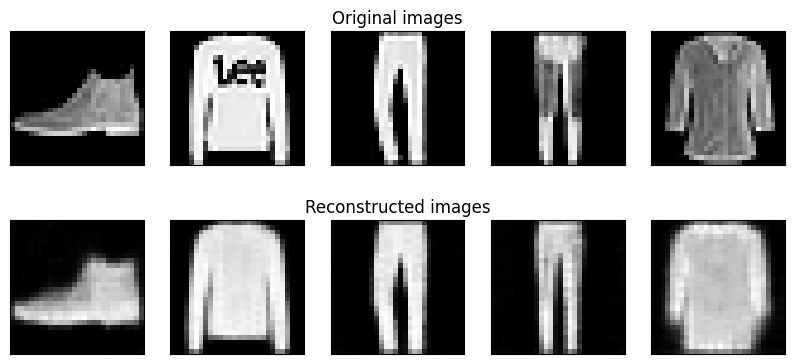

	 partial train loss (single batch): 0.019264
	 partial train loss (single batch): 0.019315
	 partial train loss (single batch): 0.020152
	 partial train loss (single batch): 0.018379
	 partial train loss (single batch): 0.019513
	 partial train loss (single batch): 0.019038
	 partial train loss (single batch): 0.021115


	 partial train loss (single batch): 0.018304
	 partial train loss (single batch): 0.019362
	 partial train loss (single batch): 0.018449
	 partial train loss (single batch): 0.019718
	 partial train loss (single batch): 0.017780


	 partial train loss (single batch): 0.019142
	 partial train loss (single batch): 0.018976
	 partial train loss (single batch): 0.019640
	 partial train loss (single batch): 0.019289
	 partial train loss (single batch): 0.019502
	 partial train loss (single batch): 0.019925
	 partial train loss (single batch): 0.018508
	 partial train loss (single batch): 0.020046


	 partial train loss (single batch): 0.018564
	 partial train loss (single batch): 0.018177
	 partial train loss (single batch): 0.019912
	 partial train loss (single batch): 0.020364
	 partial train loss (single batch): 0.019425


	 partial train loss (single batch): 0.019035
	 partial train loss (single batch): 0.020053
	 partial train loss (single batch): 0.018944
	 partial train loss (single batch): 0.018224
	 partial train loss (single batch): 0.017792
	 partial train loss (single batch): 0.018358
	 partial train loss (single batch): 0.018196
	 partial train loss (single batch): 0.018838


	 partial train loss (single batch): 0.020141
	 partial train loss (single batch): 0.019477
	 partial train loss (single batch): 0.018872
	 partial train loss (single batch): 0.018772
	 partial train loss (single batch): 0.018698


... (20 outputs left out)

	 partial train loss (single batch): 0.019648
	 partial train loss (single batch): 0.018965
	 partial train loss (single batch): 0.019053
	 partial train loss (single batch): 0.019810
	 partial train loss (single batch): 0.019221
	 partial train loss (single batch): 0.017554
	 partial train loss (single batch): 0.017772


	 partial train loss (single batch): 0.018638
	 partial train loss (single batch): 0.018725
	 partial train loss (single batch): 0.020071
	 partial train loss (single batch): 0.017458
	 partial train loss (single batch): 0.019571
	 partial train loss (single batch): 0.020471


	 partial train loss (single batch): 0.018365
	 partial train loss (single batch): 0.017091
	 partial train loss (single batch): 0.018938
	 partial train loss (single batch): 0.019537
	 partial train loss (single batch): 0.018295
	 partial train loss (single batch): 0.019633
	 partial train loss (single batch): 0.017171



 EPOCH 27/30 	 train loss 0.019 	 val loss 0.019


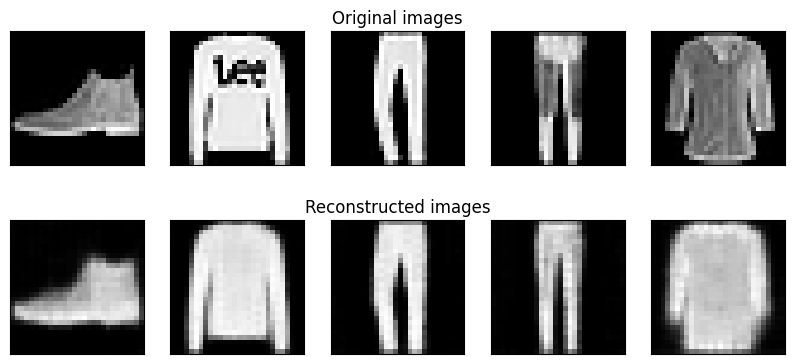

	 partial train loss (single batch): 0.019219
	 partial train loss (single batch): 0.019298
	 partial train loss (single batch): 0.020101
	 partial train loss (single batch): 0.018356
	 partial train loss (single batch): 0.019477
	 partial train loss (single batch): 0.019015
	 partial train loss (single batch): 0.021074
	 partial train loss (single batch): 0.018276


	 partial train loss (single batch): 0.019349
	 partial train loss (single batch): 0.018404
	 partial train loss (single batch): 0.019710
	 partial train loss (single batch): 0.017730
	 partial train loss (single batch): 0.019106


	 partial train loss (single batch): 0.018949
	 partial train loss (single batch): 0.019604
	 partial train loss (single batch): 0.019272
	 partial train loss (single batch): 0.019443
	 partial train loss (single batch): 0.019871
	 partial train loss (single batch): 0.018469
	 partial train loss (single batch): 0.020001
	 partial train loss (single batch): 0.018534


	 partial train loss (single batch): 0.018150
	 partial train loss (single batch): 0.019878
	 partial train loss (single batch): 0.020312
	 partial train loss (single batch): 0.019415
	 partial train loss (single batch): 0.019030


	 partial train loss (single batch): 0.020032
	 partial train loss (single batch): 0.018923
	 partial train loss (single batch): 0.018181
	 partial train loss (single batch): 0.017751
	 partial train loss (single batch): 0.018330
	 partial train loss (single batch): 0.018148
	 partial train loss (single batch): 0.018791
	 partial train loss (single batch): 0.020107


	 partial train loss (single batch): 0.019458
	 partial train loss (single batch): 0.018824
	 partial train loss (single batch): 0.018760
	 partial train loss (single batch): 0.018667
	 partial train loss (single batch): 0.018161


... (20 outputs left out)

	 partial train loss (single batch): 0.019772
	 partial train loss (single batch): 0.019196
	 partial train loss (single batch): 0.017506
	 partial train loss (single batch): 0.017761
	 partial train loss (single batch): 0.018602
	 partial train loss (single batch): 0.018659


	 partial train loss (single batch): 0.020037
	 partial train loss (single batch): 0.017444
	 partial train loss (single batch): 0.019520
	 partial train loss (single batch): 0.020424
	 partial train loss (single batch): 0.018326
	 partial train loss (single batch): 0.017036
	 partial train loss (single batch): 0.018925


	 partial train loss (single batch): 0.019502
	 partial train loss (single batch): 0.018288
	 partial train loss (single batch): 0.019633
	 partial train loss (single batch): 0.017165



 EPOCH 28/30 	 train loss 0.019 	 val loss 0.019


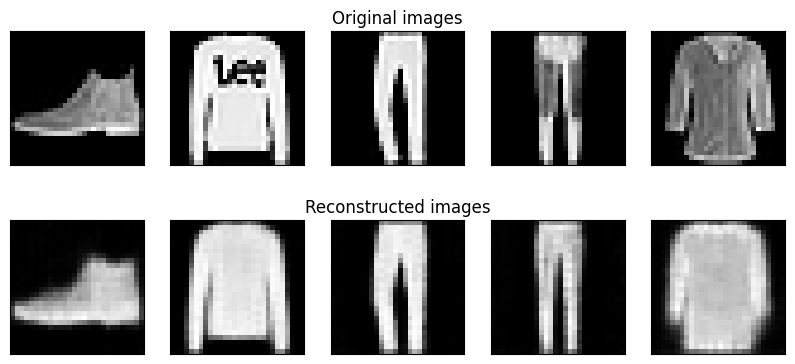

	 partial train loss (single batch): 0.019208
	 partial train loss (single batch): 0.019253
	 partial train loss (single batch): 0.020107
	 partial train loss (single batch): 0.018356
	 partial train loss (single batch): 0.019457
	 partial train loss (single batch): 0.019032
	 partial train loss (single batch): 0.021058


	 partial train loss (single batch): 0.018262
	 partial train loss (single batch): 0.019339
	 partial train loss (single batch): 0.018395
	 partial train loss (single batch): 0.019691
	 partial train loss (single batch): 0.017716
	 partial train loss (single batch): 0.019106


	 partial train loss (single batch): 0.018902
	 partial train loss (single batch): 0.019602
	 partial train loss (single batch): 0.019248
	 partial train loss (single batch): 0.019419
	 partial train loss (single batch): 0.019866
	 partial train loss (single batch): 0.018438
	 partial train loss (single batch): 0.019979
	 partial train loss (single batch): 0.018513


	 partial train loss (single batch): 0.018148
	 partial train loss (single batch): 0.019846
	 partial train loss (single batch): 0.020299
	 partial train loss (single batch): 0.019419
	 partial train loss (single batch): 0.019014
	 partial train loss (single batch): 0.020055


	 partial train loss (single batch): 0.018886
	 partial train loss (single batch): 0.018158
	 partial train loss (single batch): 0.017735
	 partial train loss (single batch): 0.018335
	 partial train loss (single batch): 0.018176
	 partial train loss (single batch): 0.018748
	 partial train loss (single batch): 0.020081


	 partial train loss (single batch): 0.019436
	 partial train loss (single batch): 0.018785
	 partial train loss (single batch): 0.018745
	 partial train loss (single batch): 0.018636
	 partial train loss (single batch): 0.018149
	 partial train loss (single batch): 0.019167
	 partial train loss (single batch): 0.018520


... (19 outputs left out)

	 partial train loss (single batch): 0.019225
	 partial train loss (single batch): 0.017852
	 partial train loss (single batch): 0.019543
	 partial train loss (single batch): 0.018886
	 partial train loss (single batch): 0.018961
	 partial train loss (single batch): 0.019720
	 partial train loss (single batch): 0.019192
	 partial train loss (single batch): 0.017476


	 partial train loss (single batch): 0.017707
	 partial train loss (single batch): 0.018564
	 partial train loss (single batch): 0.018633
	 partial train loss (single batch): 0.019995
	 partial train loss (single batch): 0.017395


	 partial train loss (single batch): 0.019498
	 partial train loss (single batch): 0.020387
	 partial train loss (single batch): 0.018285
	 partial train loss (single batch): 0.017027
	 partial train loss (single batch): 0.018882
	 partial train loss (single batch): 0.019485
	 partial train loss (single batch): 0.018237
	 partial train loss (single batch): 0.019604
	 partial train loss (single batch): 0.017102



 EPOCH 29/30 	 train loss 0.019 	 val loss 0.019


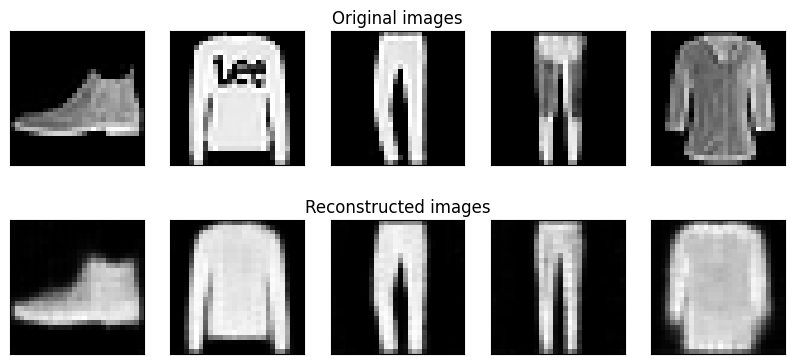

	 partial train loss (single batch): 0.019147
	 partial train loss (single batch): 0.019210
	 partial train loss (single batch): 0.020097
	 partial train loss (single batch): 0.018353
	 partial train loss (single batch): 0.019418
	 partial train loss (single batch): 0.018967
	 partial train loss (single batch): 0.021067


	 partial train loss (single batch): 0.018247
	 partial train loss (single batch): 0.019313
	 partial train loss (single batch): 0.018379
	 partial train loss (single batch): 0.019667
	 partial train loss (single batch): 0.017676
	 partial train loss (single batch): 0.019101


	 partial train loss (single batch): 0.018861
	 partial train loss (single batch): 0.019554
	 partial train loss (single batch): 0.019230
	 partial train loss (single batch): 0.019381
	 partial train loss (single batch): 0.019817
	 partial train loss (single batch): 0.018404
	 partial train loss (single batch): 0.019950


	 partial train loss (single batch): 0.018533
	 partial train loss (single batch): 0.018110
	 partial train loss (single batch): 0.019833
	 partial train loss (single batch): 0.020262
	 partial train loss (single batch): 0.019396
	 partial train loss (single batch): 0.019003


	 partial train loss (single batch): 0.020044
	 partial train loss (single batch): 0.018867
	 partial train loss (single batch): 0.018099
	 partial train loss (single batch): 0.017720
	 partial train loss (single batch): 0.018300
	 partial train loss (single batch): 0.018177
	 partial train loss (single batch): 0.018702


	 partial train loss (single batch): 0.020076
	 partial train loss (single batch): 0.019446
	 partial train loss (single batch): 0.018741
	 partial train loss (single batch): 0.018728
	 partial train loss (single batch): 0.018628
	 partial train loss (single batch): 0.018121


... (20 outputs left out)

	 partial train loss (single batch): 0.018888
	 partial train loss (single batch): 0.018944
	 partial train loss (single batch): 0.019674
	 partial train loss (single batch): 0.019124
	 partial train loss (single batch): 0.017416
	 partial train loss (single batch): 0.017656
	 partial train loss (single batch): 0.018525


	 partial train loss (single batch): 0.018592
	 partial train loss (single batch): 0.019965
	 partial train loss (single batch): 0.017354
	 partial train loss (single batch): 0.019469
	 partial train loss (single batch): 0.020331
	 partial train loss (single batch): 0.018251


	 partial train loss (single batch): 0.016976
	 partial train loss (single batch): 0.018872
	 partial train loss (single batch): 0.019470
	 partial train loss (single batch): 0.018218
	 partial train loss (single batch): 0.019589
	 partial train loss (single batch): 0.017061



 EPOCH 30/30 	 train loss 0.019 	 val loss 0.019


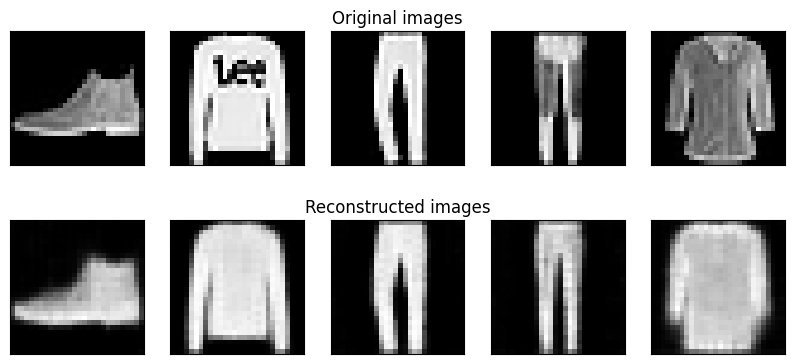

In [16]:
num_epochs = 30
history={'train_loss':[],'val_loss':[]}

for epoch in range(num_epochs):
    train_loss = train_epoch(encoder,decoder,device,train_loader,loss_fn,optim)
    val_loss = test_epoch(encoder,decoder,device,valid_loader,loss_fn)
    
    print('\n EPOCH {}/{} \t train loss {:.3f} \t val loss {:.3f}'.format(epoch + 1, num_epochs,train_loss,val_loss))
    
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    plot_ae_outputs(encoder,decoder,n=5)

In [17]:
test_epoch(encoder,decoder,device,test_loader,loss_fn).item()

0.019280681386590004

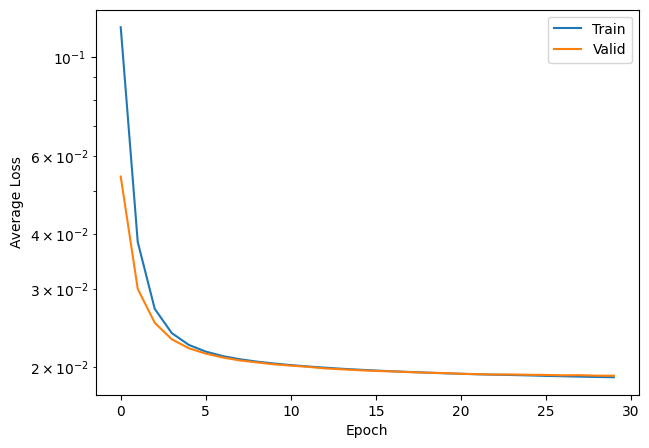

In [18]:
# Train and validation loss

plt.figure(figsize=(7,5))
plt.semilogy(history['train_loss'], label='Train')
plt.semilogy(history['val_loss'], label='Valid')
plt.xlabel('Epoch')
plt.ylabel('Average Loss')
#plt.grid()
plt.legend()
#plt.title('loss')
plt.show()

tensor([-0.5319,  0.1199,  0.4322, -0.0659])
tensor([0.5263, 0.8596, 0.9626, 0.3946])


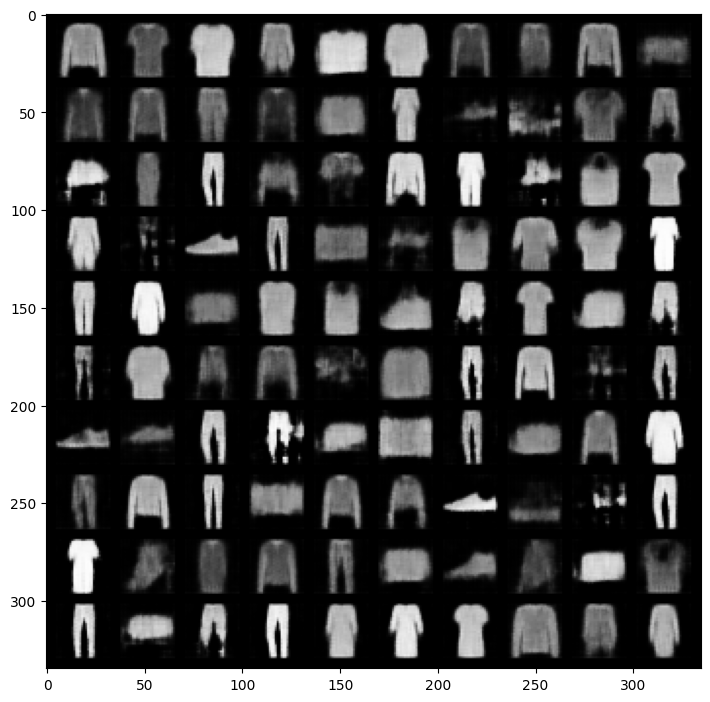

In [19]:
def show_image(img):
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))

def show_top_n(encoder, decoder, dataset, n=10):
    encoder.eval()
    decoder.eval()

    with torch.no_grad():
        # calculate mean and std of latent code, generated takining in test images as inputs 
        images, labels = map(list, zip(*[dataset[i] for i in range(10)]))
        images = torch.stack(images).to(device)
        latent = encoder(images)
        latent = latent.cpu()

        mean = latent.mean(dim=0)
        print(mean)
        std = (latent - mean).pow(2).mean(dim=0).sqrt()
        print(std)

        # sample latent vectors from the normal distribution
        latent = torch.randn(128, dim)*std + mean

        # reconstruct images from the random latent vectors
        latent = latent.to(device)
        img_recon = decoder(latent)
        img_recon = img_recon.cpu()

        fig, ax = plt.subplots(figsize=(20, 8.5))
        show_image(torchvision.utils.make_grid(img_recon[:100],10,5))
        plt.show()
        
show_top_n(encoder, decoder, test_dataset, n=10)